In [33]:
# Task 1 - Data Preparation and Feature Engineering

%pip -q install "pandas==2.2.3" "numpy==2.2.6" "requests==2.32.4" yfinance matplotlib scipy

In [34]:
#Import libraries and set the study period.

from pathlib import Path
from datetime import datetime, timezone
from io import StringIO
import time, json, platform, importlib.metadata
import numpy as np
import pandas as pd
import requests
import yfinance as yf
import matplotlib.pyplot as plt
from IPython.display import display

START = pd.Timestamp('2021-01-01')
END_EXCL = pd.Timestamp('2025-01-01')
BENCHMARK = '^GSPC'
MIN_COVERAGE = 0.95
MIN_ALIGNED_WEEKS = 52
BATCH_SIZE = 35
OBSERVATION_UTC = datetime.now(timezone.utc).isoformat()
OUT = Path('/content/task1_outputs') if Path('/content').exists() else Path.cwd() / 'task1_outputs'
OUT.mkdir(parents=True, exist_ok=True)

VERSIONS = {m: importlib.metadata.version(m) for m in ['pandas','numpy','yfinance','requests','matplotlib','scipy']}
VERSIONS.update({'python': platform.python_version(), 'retrieval_utc': OBSERVATION_UTC,
                 'start_inclusive': str(START.date()), 'end_exclusive': str(END_EXCL.date()),
                 'benchmark': BENCHMARK, 'daily_coverage_threshold': MIN_COVERAGE,
                 'min_aligned_weekly_returns': MIN_ALIGNED_WEEKS})
(OUT / 'run_metadata.json').write_text(json.dumps(VERSIONS, indent=2))
print('Output folder:', OUT)
print('Source capture time (UTC):', OBSERVATION_UTC)
print('Package versions:', VERSIONS)

Output folder: /content/task1_outputs
Source capture time (UTC): 2026-11-22T13:52:46.045307+00:00
Package versions: {'pandas': '2.2.3', 'numpy': '2.2.6', 'yfinance': '1.8.0', 'requests': '2.32.4', 'matplotlib': '3.11.2', 'scipy': '1.18.1', 'python': '3.13.18', 'retrieval_utc': '2026-11-22T13:52:46.045307+00:00', 'start_inclusive': '2021-01-01', 'end_exclusive': '2025-01-01', 'benchmark': '^GSPC', 'daily_coverage_threshold': 0.95, 'min_aligned_weekly_returns': 52}


In [35]:
# Task 1.1 - Ticker Selection and Data Acquisition
# Get and save the current S&P 500 ticker list

WIKI_URL = 'https://en.wikipedia.org/wiki/List_of_S%26P_500_companies'
resp = requests.get(WIKI_URL, headers={'User-Agent': 'Mozilla/5.0 (educational research)'}, timeout=30)
resp.raise_for_status()
wikipedia_retrieved_utc = datetime.now(timezone.utc).isoformat()
companies = pd.read_html(StringIO(resp.text))[0]
assert {'Symbol', 'Security', 'GICS Sector'}.issubset(companies.columns), companies.columns.tolist()
companies = companies[['Symbol', 'Security', 'GICS Sector']].copy()
companies['Ticker'] = (companies['Symbol'].astype(str).str.strip()
                       .str.replace('.', '-', regex=False))
assert companies['Ticker'].is_unique
companies.to_csv(OUT / 'sp500_constituents_snapshot.csv', index=False)
(OUT / 'ticker_source.json').write_text(json.dumps({
    'url': WIKI_URL, 'retrieved_utc': wikipedia_retrieved_utc,
    'count': len(companies), 'membership_caveat': 'current S&P 500 constituents, not the 2021 population'
}, indent=2))
tickers = companies['Ticker'].tolist()
print('Tickers:', len(tickers), '| sample:')
display(companies.head())

Tickers: 503 | sample:


,Symbol,Security,GICS Sector,Ticker
0,MMM,3M,Industrials,MMM
1,AOS,A. O. Smith,Industrials,AOS
2,ABT,Abbott Laboratories,Health Care,ABT
3,ABBV,AbbVie,Health Care,ABBV
4,ACN,Accenture,Information Technology,ACN


In [36]:
# Download historical daily prices, adjusted prices, volume, and the S&P 500 benchmark.
QUOTE_FIELDS = ['Open', 'High', 'Low', 'Close', 'Adj Close', 'Volume', 'Dividends', 'Stock Splits']
CACHE_FILE = None

# This normalizer accepts both supported MultiIndex orientations from yfinance.
def unpack_download(raw: pd.DataFrame, symbols: list[str]) -> list[pd.DataFrame]:
    output = []
    if raw is None or raw.empty:
        return output
    for symbol in symbols:
        if isinstance(raw.columns, pd.MultiIndex):
            if symbol in raw.columns.get_level_values(0):
                part = raw.xs(symbol, axis=1, level=0).copy()
            elif symbol in raw.columns.get_level_values(-1):
                part = raw.xs(symbol, axis=1, level=-1).copy()
            else:
                continue
        elif len(symbols) == 1:
            part = raw.copy()
        else:
            raise ValueError('Unexpected non-MultiIndex multi-symbol response; inspect data source.')
        if isinstance(part.columns, pd.MultiIndex):
            raise ValueError(f'Unexpected nested columns for {symbol}: {part.columns}')
        part = part.reindex(columns=QUOTE_FIELDS)
        if not {'Close','Adj Close','Volume'}.issubset(part.dropna(axis=1, how='all').columns):
            continue
        part.index = pd.DatetimeIndex(part.index).tz_localize(None).normalize()
        part = part.rename_axis('Date').reset_index()
        part = part[(part['Date'] >= START) & (part['Date'] < END_EXCL)]
        part = part.dropna(subset=['Close','Adj Close','Volume'], how='all')
        if part.empty:
            continue
        part.insert(1, 'Ticker', symbol)
        output.append(part)
    return output

if CACHE_FILE:
    quotes = pd.read_csv(CACHE_FILE, parse_dates=['Date'])
    required = {'Date','Ticker','Close','Adj Close','Volume'}
    if not required.issubset(quotes):
        raise ValueError('Cached snapshot lacks mandatory fields: ' + str(required - set(quotes)))
    quotes = quotes[(quotes['Date'] >= START) & (quotes['Date'] < END_EXCL)].copy()
    print('Loaded documented cached data; verify the file source and dates:', CACHE_FILE)
else:
    chunks, failed_batches = [], []
    all_symbols = tickers + [BENCHMARK]
    for start_at in range(0, len(all_symbols), BATCH_SIZE):
        batch = all_symbols[start_at:start_at + BATCH_SIZE]
        try:
            raw = yf.download(batch, start=START.strftime('%Y-%m-%d'),
                              end=END_EXCL.strftime('%Y-%m-%d'),
                              interval='1d', auto_adjust=False, actions=True,
                              group_by='ticker', multi_level_index=True,
                              progress=False, threads=True, timeout=30)
            chunks.extend(unpack_download(raw, batch))
            found = {f['Ticker'].iloc[0] for f in chunks}
            print(f'Batch {start_at // BATCH_SIZE + 1}: {len(set(batch) & found)} of {len(batch)} found')
        except Exception as exc:
            failed_batches.append({'batch': batch, 'error': str(exc)})
            print('Batch failed:', batch[:2], '...', str(exc)[:100])
        time.sleep(0.7)
    if failed_batches:
        (OUT / 'failed_batches.json').write_text(json.dumps(failed_batches, indent=2))
    if not chunks:
        raise RuntimeError('No stock data downloaded. Check Colab internet, Yahoo availability, or a documented cache.')
    quotes = pd.concat(chunks, ignore_index=True)

quotes['Date'] = pd.to_datetime(quotes['Date']).dt.tz_localize(None).dt.normalize()
for field in QUOTE_FIELDS:
    if field not in quotes:
        quotes[field] = np.nan
    quotes[field] = pd.to_numeric(quotes[field], errors='coerce')
quotes = quotes.sort_values(['Ticker','Date']).reset_index(drop=True)
quotes.to_csv(OUT / 'daily_quotes_original.csv.gz', index=False, compression='gzip')
print('Raw daily rows:', len(quotes), '| downloaded symbols:', quotes['Ticker'].nunique())
print('Date range:', quotes['Date'].min(), 'to', quotes['Date'].max())
assert BENCHMARK in quotes['Ticker'].unique(), 'Benchmark ^GSPC is missing; stop and inspect source.'
display(quotes.head())

Batch 1: 35 of 35 found
Batch 2: 35 of 35 found
Batch 3: 35 of 35 found
Batch 4: 35 of 35 found
Batch 5: 35 of 35 found


ERROR:yfinance:$FDXF: Data doesn't exist for startDate = 1609477200, endDate = 1735707600
ERROR:yfinance:
1 Failed download:
ERROR:yfinance:['FDXF']: Data doesn't exist for startDate = 1609477200, endDate = 1735707600


Batch 6: 34 of 35 found


ERROR:yfinance:$HONA: Data doesn't exist for startDate = 1609477200, endDate = 1735707600
ERROR:yfinance:
1 Failed download:
ERROR:yfinance:['HONA']: Data doesn't exist for startDate = 1609477200, endDate = 1735707600


Batch 7: 34 of 35 found
Batch 8: 35 of 35 found
Batch 9: 35 of 35 found
Batch 10: 35 of 35 found


ERROR:yfinance:$Q: Data doesn't exist for startDate = 1609477200, endDate = 1735707600
ERROR:yfinance:
1 Failed download:
ERROR:yfinance:['Q']: Data doesn't exist for startDate = 1609477200, endDate = 1735707600


... (2 outputs left out)

Batch 12: 34 of 35 found
Batch 13: 35 of 35 found


ERROR:yfinance:$VYLR: Data doesn't exist for startDate = 1609477200, endDate = 1735707600
ERROR:yfinance:
1 Failed download:
ERROR:yfinance:['VYLR']: Data doesn't exist for startDate = 1609477200, endDate = 1735707600


Batch 14: 34 of 35 found
Batch 15: 14 of 14 found
Raw daily rows: 497309 | downloaded symbols: 499
Date range: 2021-01-04 00:00:00 to 2024-12-31 00:00:00


Price,Date,Ticker,Open,High,Low,Close,Adj Close,Volume,Dividends,Stock Splits
0,2021-01-04,A,118.940002,120.089996,117.110001,118.639999,114.009132,2030700.0,0.194,0.0
1,2021-01-05,A,118.480003,120.320000,118.070000,119.610001,114.941269,2344000.0,0.000,0.0
2,2021-01-06,A,118.690002,123.879997,118.209999,122.889999,118.093231,2428500.0,0.000,0.0
3,2021-01-07,A,124.330002,127.480003,124.110001,126.160004,121.235603,1775900.0,0.000,0.0
4,2021-01-08,A,126.489998,127.639999,125.849998,127.059998,122.100456,1577200.0,0.000,0.0


In [37]:
# Task 1.2 - Data Validation and Alignment
# Check missing values, invalid prices, volumes, dates, and data coverage.
required_columns = {'Ticker','Date','Close','Adj Close','Volume'}
assert required_columns.issubset(quotes), required_columns - set(quotes)
duplicates = quotes[quotes.duplicated(['Ticker','Date'], keep=False)]
duplicates.to_csv(OUT / 'duplicate_date_rows.csv', index=False)
if len(duplicates):
    raise ValueError(f'{len(duplicates)} duplicate ticker-date rows found. Inspect before removing any.')

numeric_ok = (np.isfinite(quotes['Close']) & (quotes['Close'] > 0) &
              np.isfinite(quotes['Adj Close']) & (quotes['Adj Close'] > 0) &
              np.isfinite(quotes['Volume']) & (quotes['Volume'] >= 0))
invalid_rows = quotes.loc[~numeric_ok].copy()
invalid_rows.to_csv(OUT / 'invalid_daily_rows.csv', index=False)
clean = quotes.loc[numeric_ok].copy()

# Preserve raw data; compute quality flags on raw and valid data independently.
audit = quotes.groupby('Ticker').agg(
    raw_rows=('Date','size'),
    nonpositive_or_missing_close=('Close', lambda s: int((s.isna() | (s <= 0)).sum())),
    nonpositive_or_missing_adjusted=('Adj Close', lambda s: int((s.isna() | (s <= 0)).sum())),
    negative_or_missing_volume=('Volume', lambda s: int((s.isna() | (s < 0)).sum())),
    zero_volume_days=('Volume', lambda s: int((s == 0).sum())),
    split_events=('Stock Splits', lambda s: int((s.fillna(0) != 0).sum())),
    dividends=('Dividends', lambda s: int((s.fillna(0) != 0).sum()))
).reset_index()

market = clean[clean['Ticker'].eq(BENCHMARK)].set_index('Date').sort_index()
if len(market) < 800:
    raise ValueError('Benchmark has unexpectedly few daily dates; inspect Yahoo source before continuing.')
market_dates = pd.DatetimeIndex(market.index.unique()).sort_values()
observation_date = market_dates.max()
assert START <= observation_date < END_EXCL

# Coverage is measured against the benchmark's recorded market sessions.
per_share = []
for ticker in tickers:
    s = clean[clean['Ticker'].eq(ticker)].sort_values('Date')
    dates = pd.DatetimeIndex(s['Date'])
    present = dates.isin(market_dates).sum()
    per_share.append({
        'Ticker': ticker,
        'valid_daily_rows': len(s),
        'market_sessions_observed': int(present),
        'market_sessions_total': len(market_dates),
        'daily_coverage': present / len(market_dates),
        'first_valid_date': s['Date'].min() if len(s) else pd.NaT,
        'last_valid_date': s['Date'].max() if len(s) else pd.NaT,
        'has_observation_date': bool(observation_date in dates),
        'last_80_sessions_complete': bool(pd.Index(market_dates[-80:]).isin(dates).all())
    })
coverage = pd.DataFrame(per_share)
audit = companies[['Ticker','Security','GICS Sector']].merge(coverage, on='Ticker', how='left').merge(audit, on='Ticker', how='left')

# Large adjusted-price changes may reflect market moves, errors, or corporate actions.
price_jump = clean.sort_values(['Ticker','Date']).copy()
price_jump['AdjustedDailyReturn'] = price_jump.groupby('Ticker')['Adj Close'].pct_change(fill_method=None)
suspect_jumps = price_jump.loc[price_jump['AdjustedDailyReturn'].abs() > 0.50]
suspect_jumps.to_csv(OUT / 'price_jumps_review.csv', index=False)
audit.to_csv(OUT / 'daily_validation_audit.csv', index=False)
clean.to_csv(OUT / 'daily_quotes_valid.csv.gz', index=False, compression='gzip')
print('Observation date:', observation_date.date(), '| benchmark sessions:', len(market_dates))
print('Invalid daily rows:', len(invalid_rows), '| adjusted-price jumps >50%:', len(suspect_jumps))
print('Shares with >=95% daily coverage:', int((coverage.daily_coverage >= MIN_COVERAGE).sum()))
display(audit.head())

Observation date: 2024-12-31 | benchmark sessions: 1005
Invalid daily rows: 0 | adjusted-price jumps >50%: 4
Shares with >=95% daily coverage: 489


,Ticker,Security,GICS Sector,valid_daily_rows,market_sessions_observed,market_sessions_total,daily_coverage,first_valid_date,last_valid_date,has_observation_date,last_80_sessions_complete,raw_rows,nonpositive_or_missing_close,nonpositive_or_missing_adjusted,negative_or_missing_volume,zero_volume_days,split_events,dividends
0,MMM,3M,Industrials,1005,1005,1005,1.0,2021-01-04,2024-12-31,True,True,1005.0,0.0,0.0,0.0,0.0,1.0,16.0
1,AOS,A. O. Smith,Industrials,1005,1005,1005,1.0,2021-01-04,2024-12-31,True,True,1005.0,0.0,0.0,0.0,0.0,0.0,16.0
2,ABT,Abbott Laboratories,Health Care,1005,1005,1005,1.0,2021-01-04,2024-12-31,True,True,1005.0,0.0,0.0,0.0,0.0,0.0,16.0
3,ABBV,AbbVie,Health Care,1005,1005,1005,1.0,2021-01-04,2024-12-31,True,True,1005.0,0.0,0.0,0.0,0.0,0.0,16.0
4,ACN,Accenture,Information Technology,1005,1005,1005,1.0,2021-01-04,2024-12-31,True,True,1005.0,0.0,0.0,0.0,0.0,0.0,16.0


In [38]:
# Task 1.3 - Weekly Return and Weekly Beta
# Task 1.3.1 - Mean Weekly Return
# Task 1.3.2 - Weekly Beta
# Calculate Friday-ending returns and compare each stock with the benchmark.
def complete_calendar_fridays(weekly_index: pd.DatetimeIndex, start: pd.Timestamp,
                              end_exclusive: pd.Timestamp) -> pd.DatetimeIndex:
    """Keep Mon–Fri calendar weeks wholly inside [start, end_exclusive)."""
    fridays = pd.DatetimeIndex(weekly_index)
    week_mondays = fridays - pd.Timedelta(days=4)
    return fridays[(week_mondays >= start) & (fridays < end_exclusive)]

def paired_weekly_metrics(stock_returns: pd.Series, market_returns: pd.Series, min_weeks=52):
    paired = pd.concat([stock_returns.rename('stock'), market_returns.rename('market')], axis=1).dropna()
    n = len(paired)
    if n < min_weeks or paired['market'].var(ddof=1) <= 0:
        return {'MeanWeeklyReturn': np.nan, 'WeeklyBeta': np.nan, 'AlignedWeeks': n}
    return {'MeanWeeklyReturn': paired['stock'].mean(),
            'WeeklyBeta': paired['stock'].cov(paired['market']) / paired['market'].var(ddof=1),
            'AlignedWeeks': n}

# Task 01.3.1 - Convert adjusted daily closing prices to weekly returns.
wide_adj = clean.pivot(index='Date', columns='Ticker', values='Adj Close').reindex(market_dates)
weekly_price = wide_adj.resample('W-FRI').last()
full_weeks = complete_calendar_fridays(weekly_price.index, START, END_EXCL)
weekly_price = weekly_price.loc[full_weeks].copy()
weekly_returns = weekly_price.pct_change(fill_method=None)
if BENCHMARK not in weekly_returns:
    raise ValueError('Missing benchmark in weekly return matrix')

# Task 01.3.2 - Calculate each share's mean weekly return and weekly beta.
risk_results = []
for ticker in tickers:
    if ticker not in weekly_returns.columns:
        risk_results.append({'Ticker': ticker, 'MeanWeeklyReturn': np.nan,
                             'WeeklyBeta': np.nan, 'AlignedWeeks': 0})
        continue
    metrics = paired_weekly_metrics(weekly_returns[ticker], weekly_returns[BENCHMARK], MIN_ALIGNED_WEEKS)
    risk_results.append({'Ticker': ticker, **metrics})
risk = pd.DataFrame(risk_results)
weekly_price.to_csv(OUT / 'weekly_adjusted_price.csv')
weekly_returns.to_csv(OUT / 'weekly_returns.csv')
risk.to_csv(OUT / 'weekly_risk_features.csv', index=False)
print('Full calendar weeks:', len(weekly_price), '| weekly return dates:',
      weekly_returns.index.min().date(), 'through', weekly_returns.index.max().date())
print('Paired weekly metrics for first rows:')
display(risk.head())

Full calendar weeks: 208 | weekly return dates: 2021-01-08 through 2024-12-27
Paired weekly metrics for first rows:


,Ticker,MeanWeeklyReturn,WeeklyBeta,AlignedWeeks
0,MMM,0.001142,0.869078,207
1,AOS,0.001991,1.042804,207
2,ABT,0.000971,0.583543,207
3,ABBV,0.003749,0.425366,207
4,ACN,0.002376,1.143299,207


In [39]:
# Task 1.4 - Adapted RFM Calculations
# Task 1.4.1 - Recency
# Task 1.4.2 - Frequency
# Task 1.4.3 - Monetary
# Identify unusual volume using the previous 20 sessions: calculate the RFM features.
# Check if today's volume is more than twice the previous 20-session average.
def unusual_volume_flags(volume: pd.Series) -> pd.DataFrame:
    """Input indexed on the full market-session calendar; never fill missing volumes."""
    volume = pd.to_numeric(volume, errors='coerce').astype(float)
    preceding_20_mean = volume.shift(1).rolling(window=20, min_periods=20).mean()
    threshold = 2 * preceding_20_mean
    event = (volume > threshold) & preceding_20_mean.notna() & volume.notna()
    return pd.DataFrame({'Volume': volume, 'Prior20MeanVolume': preceding_20_mean,
                         'Threshold': threshold, 'HighVolumeEvent': event})

def compute_rfm(stock_daily: pd.DataFrame, calendar: pd.DatetimeIndex,
                observation: pd.Timestamp) -> tuple[dict, pd.DataFrame]:
    """Return an auditable stock's RFM and its aligned daily event timeline."""
    s = stock_daily.set_index('Date').sort_index().reindex(calendar)
    if len(calendar) < 80:
        return {'R': np.nan,'F': np.nan,'M_USD': np.nan,
                'RFM_Status': 'Fewer than 80 benchmark sessions', 'LastHighVolumeDate': pd.NaT}, pd.DataFrame()
    last80 = s.iloc[-80:]
    if last80[['Close','Volume']].isna().any().any():
        return {'R': np.nan,'F': np.nan,'M_USD': np.nan,
                'RFM_Status': 'Incomplete final 80 market sessions', 'LastHighVolumeDate': pd.NaT}, pd.DataFrame()
    timeline = unusual_volume_flags(s['Volume'])
    timeline['Close'] = s['Close']
    timeline['ApproxDailyTradedUSD'] = s['Close'] * s['Volume']
    history_events = timeline.index[timeline['HighVolumeEvent']]
    latest_event = history_events.max() if len(history_events) else pd.NaT
    # Task 1.4.1 - Recency: Calendar days since the most recent unusual-volume day.
    R = (observation - latest_event).days if pd.notna(latest_event) else np.nan
    final60 = timeline.iloc[-60:]
    # Task 1.4.2 - Frequency: Count unusual-volume days in the final 60 sessions.
    F = int(final60['HighVolumeEvent'].sum())
    # Task 1.4.3 - Monetary: Sum Close multiplied by Volume in the final 60 sessions.
    M = float(final60['ApproxDailyTradedUSD'].sum(min_count=60))
    status = 'Valid' if pd.notna(R) else 'No qualifying historical event'
    return {'R': R,'F': F,'M_USD': M,
            'RFM_Status': status, 'LastHighVolumeDate': latest_event}, timeline

rfm_results = []
example_ticker = 'AAPL' if 'AAPL' in tickers else tickers[0]
example_timeline = None
for ticker in tickers:
    d = clean.loc[clean['Ticker'].eq(ticker), ['Date','Close','Volume']].copy()
    metrics, timeline = compute_rfm(d, market_dates, observation_date)
    rfm_results.append({'Ticker': ticker, **metrics})
    if ticker == example_ticker:
        example_timeline = timeline
rfm = pd.DataFrame(rfm_results)
rfm.to_csv(OUT / 'rfm_features_all_shares.csv', index=False)
print('RFM eligible:', int(rfm.RFM_Status.eq('Valid').sum()),
      '| no qualifying event:', int(rfm.RFM_Status.eq('No qualifying historical event').sum()))
display(rfm.head())

# Task 1.4 - Save a worked RFM example for one share.
if example_timeline is not None and not example_timeline.empty:
    worked = example_timeline.iloc[-80:].copy()
    worked.index.name = 'Date'
    worked['Window60'] = [False] * 20 + [True] * 60
    worked.to_csv(OUT / f'{example_ticker}_rfm_worked_example_80_sessions.csv')
    print(f'Worked audit: {example_ticker}; last 80 dates and event rule (note first 20 are baseline)')
    display(worked.tail(12))
    display(rfm[rfm['Ticker'].eq(example_ticker)])

RFM eligible: 498 | no qualifying event: 0


,Ticker,R,F,M_USD,RFM_Status,LastHighVolumeDate
0,MMM,11.0,4.0,2.599146e+10,Valid,2024-12-20
1,AOS,11.0,2.0,4.748980e+09,Valid,2024-12-20
2,ABT,11.0,1.0,3.523027e+10,Valid,2024-12-20
3,ABBV,11.0,3.0,6.837054e+10,Valid,2024-12-20
4,ACN,11.0,2.0,5.199430e+10,Valid,2024-12-20


Worked audit: AAPL; last 80 dates and event rule (note first 20 are baseline)


,Volume,Prior20MeanVolume,Threshold,HighVolumeEvent,Close,ApproxDailyTradedUSD,Window60
Date,,,,,,,
2024-12-13,33155300.0,42754595.0,85509190.0,False,248.130005,8.226825e+09,True
2024-12-16,51694800.0,42166165.0,84332330.0,False,251.039993,1.297746e+10,True
2024-12-17,51356400.0,42354720.0,84709440.0,False,253.479996,1.301782e+10,True
2024-12-18,56774100.0,42690855.0,85381710.0,False,248.050003,1.408282e+10,True
2024-12-19,60882300.0,43718970.0,87437940.0,False,249.789993,1.520779e+10,True
2024-12-20,147495300.0,45004605.0,90009210.0,True,254.490005,3.753608e+10,True
2024-12-23,40858800.0,50273955.0,100547910.0,False,255.270004,1.043003e+10,True
2024-12-24,23234700.0,50408480.0,100816960.0,False,258.200012,5.999200e+09,True
2024-12-26,27237100.0,47062575.0,94125150.0,False,259.019989,7.054953e+09,True


,Ticker,R,F,M_USD,RFM_Status,LastHighVolumeDate
38,AAPL,11.0,2.0,6.233034e+11,Valid,2024-12-20


In [41]:
# Task 1.5 - Metric Interpretation and Supporting Evidence
# Save feature summaries, the final share list, and reasons for exclusions.
feature_all = (companies[['Ticker','Security','GICS Sector']]
               .merge(coverage, on='Ticker', how='left')
               .merge(risk, on='Ticker', how='left')
               .merge(rfm, on='Ticker', how='left'))

def reasons_for(row):
    reasons=[]
    if not np.isfinite(row['daily_coverage']) or row['daily_coverage'] == 0:
        reasons.append('No valid downloaded daily data')
    elif row['daily_coverage'] < MIN_COVERAGE:
        reasons.append(f'Daily coverage below {MIN_COVERAGE:.0%}')
    if not row['has_observation_date']:
        reasons.append('Missing final benchmark observation date')
    if not row['last_80_sessions_complete']:
        reasons.append('Incomplete last 80 market sessions')
    if pd.isna(row['AlignedWeeks']) or row['AlignedWeeks'] < MIN_ALIGNED_WEEKS:
        reasons.append('Insufficient aligned weekly returns')
    if pd.isna(row['MeanWeeklyReturn']) or pd.isna(row['WeeklyBeta']):
        reasons.append('Undefined weekly return or beta')
    if row['RFM_Status'] != 'Valid':
        reasons.append(str(row['RFM_Status']))
    return '; '.join(reasons) if reasons else 'Included'

feature_all['InclusionDecision'] = feature_all.apply(reasons_for, axis=1)
feature_all['Included'] = feature_all['InclusionDecision'].eq('Included')
feature_all.to_csv(OUT / 'share_inclusion_and_exclusion_log.csv', index=False)
features = feature_all.loc[feature_all['Included']].copy()
required_features = ['MeanWeeklyReturn','WeeklyBeta','R','F','M_USD']
assert not features[required_features].isna().any().any(), 'Investigate missing required features'
assert features['Ticker'].is_unique
features.to_csv(OUT / 'task1_common_feature_table.csv', index=False)

print('Source tickers:', len(tickers))
print('Included for BOTH Task 2 feature matrices:', len(features))
print('Excluded:', len(feature_all) - len(features))
print('Reason frequencies:')
print(feature_all.loc[~feature_all['Included'], 'InclusionDecision'].value_counts().head(15))
print('Feature summaries (raw units; weekly mean return is a decimal fraction):')
display(features[required_features].describe().T)
display(features[['Ticker','Security','GICS Sector'] + required_features].head(10))

Source tickers: 503
Included for BOTH Task 2 feature matrices: 489
Excluded: 14
Reason frequencies:
InclusionDecision
Daily coverage below 95%                                                                                                                                                                                                   6
No valid downloaded daily data; Missing final benchmark observation date; Incomplete last 80 market sessions; Insufficient aligned weekly returns; Undefined weekly return or beta; Incomplete final 80 market sessions    5
Daily coverage below 95%; Insufficient aligned weekly returns; Undefined weekly return or beta                                                                                                                             3
Name: count, dtype: int64
Feature summaries (raw units; weekly mean return is a decimal fraction):


,count,mean,std,min,25%,50%,75%,max
MeanWeeklyReturn,489.0,2.864153e-03,2.647811e-03,-4.468093e-03,1.182857e-03,2.635542e-03,4.207597e-03,1.777248e-02
WeeklyBeta,489.0,9.736009e-01,4.061762e-01,5.545346e-02,6.666519e-01,9.480434e-01,1.179165e+00,3.778560e+00
R,489.0,2.037014e+01,2.128524e+01,4.000000e+00,1.100000e+01,1.100000e+01,1.500000e+01,2.220000e+02
F,489.0,2.987730e+00,1.327458e+00,0.000000e+00,2.000000e+00,3.000000e+00,4.000000e+00,8.000000e+00
M_USD,489.0,3.925106e+10,1.287563e+11,1.297483e+09,1.025033e+10,1.665860e+10,3.201227e+10,1.847697e+12


,Ticker,Security,GICS Sector,MeanWeeklyReturn,WeeklyBeta,R,F,M_USD
0,MMM,3M,Industrials,0.001142,0.869078,11.0,4.0,2.599146e+10
1,AOS,A. O. Smith,Industrials,0.001991,1.042804,11.0,2.0,4.748980e+09
2,ABT,Abbott Laboratories,Health Care,0.000971,0.583543,11.0,1.0,3.523027e+10
3,ABBV,AbbVie,Health Care,0.003749,0.425366,11.0,3.0,6.837054e+10
4,ACN,Accenture,Information Technology,0.002376,1.143299,11.0,2.0,5.199430e+10
5,ADBE,Adobe Inc.,Information Technology,0.000990,1.553525,18.0,3.0,1.030403e+11
6,AMD,Advanced Micro Devices,Information Technology,0.003624,1.877622,18.0,4.0,3.131659e+11
7,AES,AES Corporation,Utilities,-0.001420,1.143912,54.0,3.0,1.119578e+10
8,AFL,Aflac,Financials,0.005004,0.707196,11.0,2.0,1.328456e+10
9,A,Agilent Technologies,Health Care,0.001121,1.074725,11.0,2.0,1.400180e+10


In [42]:
# Task 1.5 - Supporting Evidence and Calculation Checks
# Test weekly returns and RFM calculations using simple examples.
# Strict threshold: a day at exactly 2x the prior mean must NOT qualify.
synthetic_idx = pd.bdate_range('2024-03-01', periods=21)
for last_volume, should_qualify in [(200, False), (201, True)]:
    vol = pd.Series([100.0]*20 + [last_volume], index=synthetic_idx)
    f = unusual_volume_flags(vol)
    assert f.iloc[-1]['Prior20MeanVolume'] == 100.0
    assert bool(f.iloc[-1]['HighVolumeEvent']) == should_qualify

# A missing calendar week must not create a two-week return.
p = pd.Series([100.0, np.nan, 110.0, 121.0],
              index=pd.date_range('2024-01-05', periods=4, freq='W-FRI'))
r = p.pct_change(fill_method=None)
assert pd.isna(r.iloc[2]) and abs(r.iloc[3] - 0.1) < 1e-10

# A Friday event followed by Monday observation is three CALENDAR days.
friday = pd.Timestamp('2024-05-03'); monday = pd.Timestamp('2024-05-06')
assert (monday - friday).days == 3

# No high-volume event => missing Recency, not zero.
calendar = pd.bdate_range('2024-01-01', periods=100)
flat = pd.DataFrame({'Date': calendar,'Close':100.0,'Volume':100.0})
flat_rfm, _ = compute_rfm(flat, calendar, calendar[-1])
assert pd.isna(flat_rfm['R']) and flat_rfm['F'] == 0
assert abs(flat_rfm['M_USD'] - 60*100*100) < 1e-10

# A final-day event must give R=0, F=1 and an unchanged 60-day monetary formula.
last_event = flat.copy(); last_event.loc[last_event.index[-1], 'Volume'] = 250.0
a, _ = compute_rfm(last_event, calendar, calendar[-1])
assert a['R'] == 0 and a['F'] == 1
assert abs(a['M_USD'] - (59*100*100+100*250)) < 1e-10

print('All synthetic boundary tests passed. Now independently inspect the REAL-data audit files.')

All synthetic boundary tests passed. Now independently inspect the REAL-data audit files.


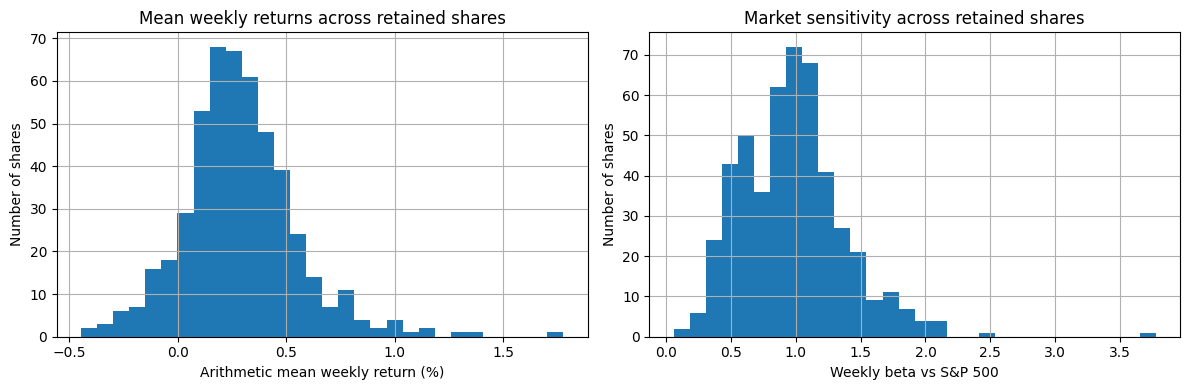

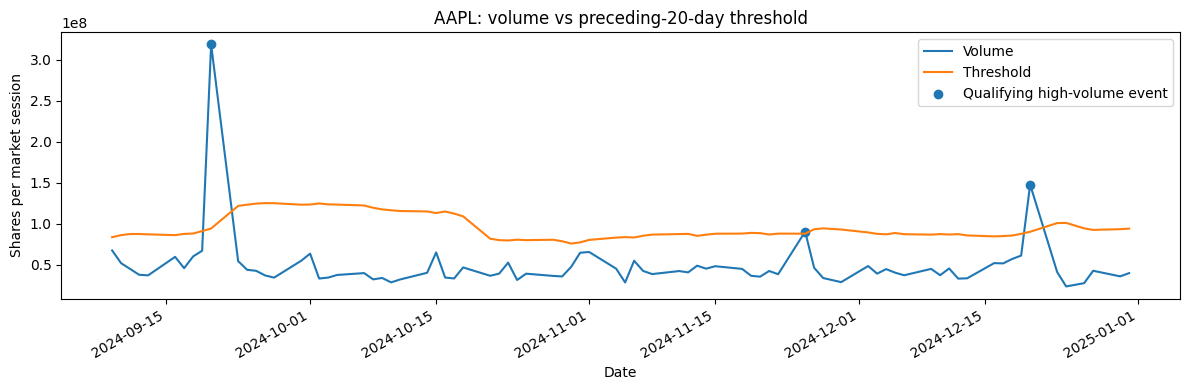

In [43]:
# Task 1.5 - Metric Interpretation and Supporting Visualisations
# Create graphs to help explain the risk, return, and volume measures.
if len(features):
    fig, axes = plt.subplots(1, 2, figsize=(12, 4))
    features['MeanWeeklyReturn'].mul(100).hist(ax=axes[0], bins=30)
    axes[0].set(xlabel='Arithmetic mean weekly return (%)', ylabel='Number of shares',
                title='Mean weekly returns across retained shares')
    features['WeeklyBeta'].hist(ax=axes[1], bins=30)
    axes[1].set(xlabel='Weekly beta vs S&P 500', ylabel='Number of shares',
                title='Market sensitivity across retained shares')
    plt.tight_layout(); plt.savefig(OUT / 'risk_return_feature_distributions.png', dpi=150); plt.show()

if example_timeline is not None and not example_timeline.empty:
    ex = example_timeline.iloc[-80:]
    ax = ex[['Volume','Threshold']].plot(figsize=(12, 4), title=f'{example_ticker}: volume vs preceding-20-day threshold')
    highlighted = ex.loc[ex['HighVolumeEvent']]
    ax.scatter(highlighted.index, highlighted['Volume'], marker='o', label='Qualifying high-volume event')
    ax.set_ylabel('Shares per market session')
    ax.legend(); plt.tight_layout()
    plt.savefig(OUT / f'{example_ticker}_volume_threshold.png', dpi=150); plt.show()

In [44]:
# Task 1 - Save Outputs for Task 1 Submission
# Export the calculated tables, audit logs, and charts into one ZIP file.
# Package the outputs produced by the REAL Colab run for your own inspection and archive.
import shutil
zip_file = shutil.make_archive(str(OUT), 'zip', root_dir=OUT)
print('Archive created:', zip_file)
print('Required audit artifacts:')
for p in sorted(OUT.glob('*')):
    print(f'- {p.name}: {p.stat().st_size/1024:.1f} KB')

Archive created: /content/task1_outputs.zip
Required audit artifacts:
- AAPL_rfm_worked_example_80_sessions.csv: 7.2 KB
- AAPL_volume_threshold.png: 91.2 KB
- daily_quotes_original.csv.gz: 12927.3 KB
- daily_quotes_valid.csv.gz: 12927.3 KB
- daily_validation_audit.csv: 57.7 KB
- duplicate_date_rows.csv: 0.1 KB
- invalid_daily_rows.csv: 0.1 KB
- price_jumps_review.csv: 0.6 KB
- rfm_features_all_shares.csv: 23.9 KB
- risk_return_feature_distributions.png: 55.3 KB
- run_metadata.json: 0.4 KB
- share_inclusion_and_exclusion_log.csv: 93.8 KB
- sp500_constituents_snapshot.csv: 18.9 KB
- task1_common_feature_table.csv: 90.2 KB
- task2_additional_exclusions.csv: 0.1 KB
- task2_input_original_units.csv: 90.2 KB
- ticker_source.json: 0.2 KB
- weekly_adjusted_price.csv: 1829.8 KB
- weekly_returns.csv: 2109.5 KB
- weekly_risk_features.csv: 23.7 KB


In [45]:
# Download Task 1 results as a ZIP file

from google.colab import files

files.download('/content/task1_outputs.zip')

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

In [46]:
# Task 2: Stock Segmentation and Sensitivity Analysis

In [94]:
# Task 2 - Import libraries and initialise the output directory.
from pathlib import Path
import os, sys, json, zipfile, shutil, math, platform, warnings
from datetime import datetime, timezone
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from matplotlib import cm
from scipy.cluster.hierarchy import linkage, dendrogram
from sklearn.cluster import AgglomerativeClustering, KMeans
from sklearn.preprocessing import StandardScaler
from sklearn.metrics import silhouette_score, adjusted_rand_score
from sklearn.decomposition import PCA
import sklearn, scipy
from IPython.display import display, Markdown

SEED = 42
np.random.seed(SEED)
ROOT = Path('/content') if Path('/content').exists() else Path.cwd()
OUT = ROOT / 'task2_outputs'
OUT.mkdir(parents=True, exist_ok=True)
INPUT_ZIP = None  # Detected in the next cell, or uploaded when prompted.
print('Python:', sys.version.split()[0], '| pandas:', pd.__version__, '| numpy:', np.__version__)
print('scikit-learn:', sklearn.__version__, '| scipy:', scipy.__version__)
print('Output folder:', OUT)

Python: 3.13.18 | pandas: 2.2.3 | numpy: 2.4.6
scikit-learn: 1.6.1 | scipy: 1.18.1
Output folder: /content/task2_outputs


In [95]:
# Read the Task 1 ZIP. In Colab, upload task1_outputs.zip when asked.
candidates = [ROOT / 'task1_outputs.zip', Path('/mnt/data/task1_outputs.zip'), Path.cwd() / 'task1_outputs.zip']
found = next((p for p in candidates if p.exists()), None)
if found is None:
    try:
        from google.colab import files
        print('Please upload task1_outputs.zip now.')
        uploaded = files.upload()
        if 'task1_outputs.zip' not in uploaded:
            raise FileNotFoundError('Upload the file named task1_outputs.zip, not the notebook.')
        found = ROOT / 'task1_outputs.zip'
        if not found.exists():  # Some runtimes store uploads in the working directory.
            found = Path.cwd() / 'task1_outputs.zip'
    except ImportError:
        raise FileNotFoundError('Put task1_outputs.zip in the notebook working folder and run again.')
INPUT_ZIP = found
with zipfile.ZipFile(INPUT_ZIP) as z:
    expected = {'task1_common_feature_table.csv', 'sp500_constituents_snapshot.csv',
                'run_metadata.json', 'share_inclusion_and_exclusion_log.csv'}
    absent = sorted(expected - set(z.namelist()))
    if absent:
        raise ValueError(f'Task 1 ZIP is missing required items: {absent}')
    raw = pd.read_csv(z.open('task1_common_feature_table.csv'))
    constituents = pd.read_csv(z.open('sp500_constituents_snapshot.csv'))
    inclusion_log = pd.read_csv(z.open('share_inclusion_and_exclusion_log.csv'))
    task1_metadata = json.loads(z.read('run_metadata.json').decode('utf-8'))
    retrieval_metadata = json.loads(z.read('ticker_source.json').decode('utf-8')) if 'ticker_source.json' in z.namelist() else {}
    daily_audit = pd.read_csv(z.open('daily_validation_audit.csv')) if 'daily_validation_audit.csv' in z.namelist() else None
print('Read:', INPUT_ZIP.name, '| task1 feature rows:', len(raw))
print('Task 1 observation window:', task1_metadata.get('start_inclusive'), 'to', task1_metadata.get('end_exclusive'))

Read: task1_outputs.zip | task1 feature rows: 489
Task 1 observation window: 2021-01-01 to 2025-01-01


In [96]:
# Task 2.1 - Reload the exact Task 1 feature table before clustering.
# This prevents a different notebook's `raw` DataFrame from being reused accidentally.
if INPUT_ZIP is None or not Path(INPUT_ZIP).is_file():
    raise FileNotFoundError('Run the Input cell first and upload task1_outputs.zip.')
with zipfile.ZipFile(INPUT_ZIP) as task1_archive:
    if 'task1_common_feature_table.csv' not in task1_archive.namelist():
        raise FileNotFoundError('Wrong ZIP: task1_common_feature_table.csv is missing.')
    task1_features = pd.read_csv(task1_archive.open('task1_common_feature_table.csv'))
task1_features.columns = task1_features.columns.astype(str).str.strip()
print('Task 1 ZIP:', INPUT_ZIP)
print('Feature table:', task1_features.shape)
print('Available columns:', task1_features.columns.tolist())

# Task 2.1 - Use exactly the same shares in every baseline clustering model.
needed = ['Ticker','Security','GICS Sector','MeanWeeklyReturn','WeeklyBeta','R','F','M_USD']
missing_columns = sorted(set(needed)-set(task1_features.columns))
if missing_columns:
    raise KeyError(f'Missing Task 1 feature columns: {missing_columns}')
if 'Included' in task1_features.columns:
    data = task1_features.loc[raw['Included'].astype(str).str.lower().eq('true')].copy()
else:
    data = task1_features.copy()  # Task 1 common table can already contain only included shares.
if data['Ticker'].duplicated().any():
    raise ValueError('Duplicate ticker in common feature table; investigate before clustering.')
for field in ['MeanWeeklyReturn','WeeklyBeta','R','F','M_USD']:
    data[field] = pd.to_numeric(data[field], errors='coerce')
finite = np.isfinite(data[['MeanWeeklyReturn','WeeklyBeta','R','F','M_USD']].to_numpy(dtype=float)).all(axis=1)
nonnegative = (data[['R','F','M_USD']] >= 0).all(axis=1)
sector_ok = data['GICS Sector'].notna() & data['GICS Sector'].astype(str).str.strip().ne('')
mask = finite & nonnegative & sector_ok
excluded_task2 = data.loc[~mask, ['Ticker','Security','GICS Sector','MeanWeeklyReturn','WeeklyBeta','R','F','M_USD']].copy()
excluded_task2['Reason'] = 'Missing/nonfinite values, invalid nonnegative RFM or missing GICS sector'
excluded_task2.to_csv(OUT/'task2_additional_exclusions.csv', index=False)
shares = data.loc[mask].copy().sort_values('Ticker').reset_index(drop=True)
if len(shares)<10:
    raise ValueError('Insufficient valid shares for clustering.')
shares.to_csv(OUT/'task2_input_original_units.csv', index=False)
features_risk_raw = shares[['MeanWeeklyReturn','WeeklyBeta']].copy()
features_rfm_raw = shares[['R','F','M_USD']].copy()
assert (features_risk_raw.index == features_rfm_raw.index).all()
assert shares['Ticker'].is_unique
print('Common valid share set:', len(shares), '| Task 2 additional exclusions:', len(excluded_task2))
print('Sectors:', shares['GICS Sector'].nunique())
display(shares[needed].head(8))

Task 1 ZIP: /content/task1_outputs.zip
Feature table: (489, 21)
Available columns: ['Ticker', 'Security', 'GICS Sector', 'valid_daily_rows', 'market_sessions_observed', 'market_sessions_total', 'daily_coverage', 'first_valid_date', 'last_valid_date', 'has_observation_date', 'last_80_sessions_complete', 'MeanWeeklyReturn', 'WeeklyBeta', 'AlignedWeeks', 'R', 'F', 'M_USD', 'RFM_Status', 'LastHighVolumeDate', 'InclusionDecision', 'Included']
Common valid share set: 489 | Task 2 additional exclusions: 0
Sectors: 11


,Ticker,Security,GICS Sector,MeanWeeklyReturn,WeeklyBeta,R,F,M_USD
0,A,Agilent Technologies,Health Care,0.001121,1.074725,11.0,2.0,1.400180e+10
1,AAPL,Apple Inc.,Information Technology,0.003930,1.174835,11.0,2.0,6.233034e+11
2,ABBV,AbbVie,Health Care,0.003749,0.425366,11.0,3.0,6.837054e+10
3,ABNB,Airbnb,Consumer Discretionary,0.001475,1.472709,11.0,3.0,3.652850e+10
4,ABT,Abbott Laboratories,Health Care,0.000971,0.583543,11.0,1.0,3.523027e+10
5,ACGL,Arch Capital Group,Financials,0.005289,0.586638,11.0,4.0,1.196213e+10
6,ACN,Accenture,Information Technology,0.002376,1.143299,11.0,2.0,5.199430e+10
7,ADBE,Adobe Inc.,Information Technology,0.000990,1.553525,18.0,3.0,1.030403e+11


,Feature,Skewness,Minimum,Median,Maximum,IQR_Flagged
0,MeanWeeklyReturn,0.862,-4.000000e-03,3.000000e-03,1.800000e-02,15
1,WeeklyBeta,1.107,5.500000e-02,9.480000e-01,3.779000e+00,10
2,R,3.657,4.000000e+00,1.100000e+01,2.220000e+02,113
3,F,0.429,0.000000e+00,3.000000e+00,8.000000e+00,2
4,M_USD,11.719,1.297483e+09,1.665860e+10,1.847697e+12,46


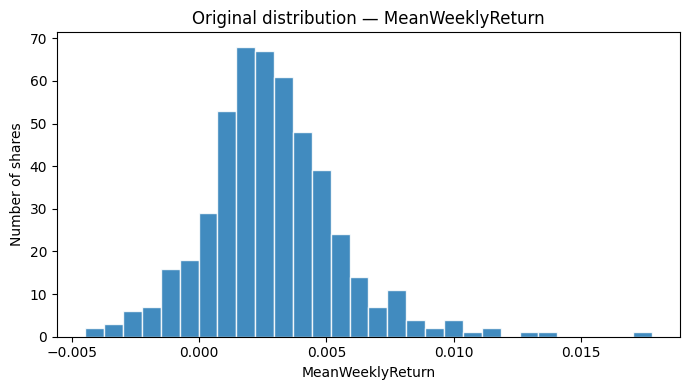

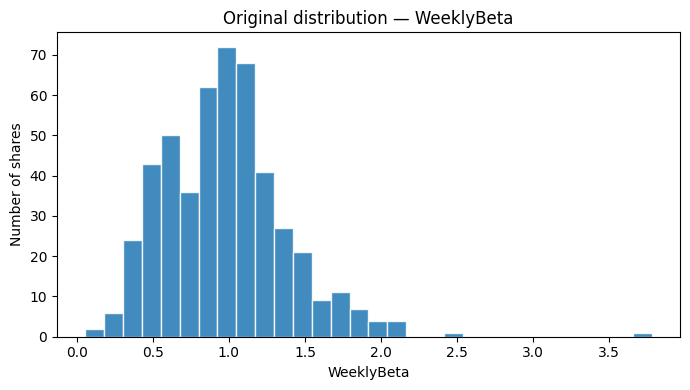

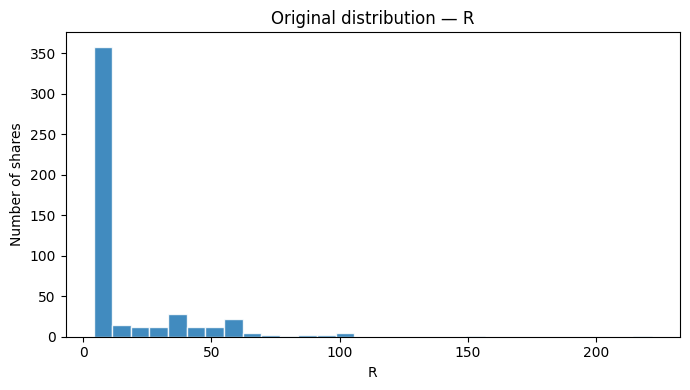

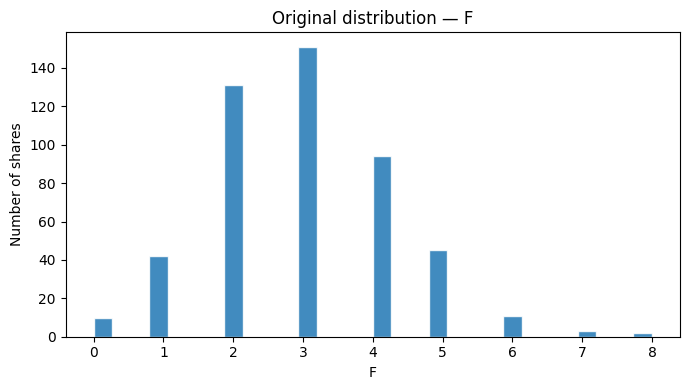

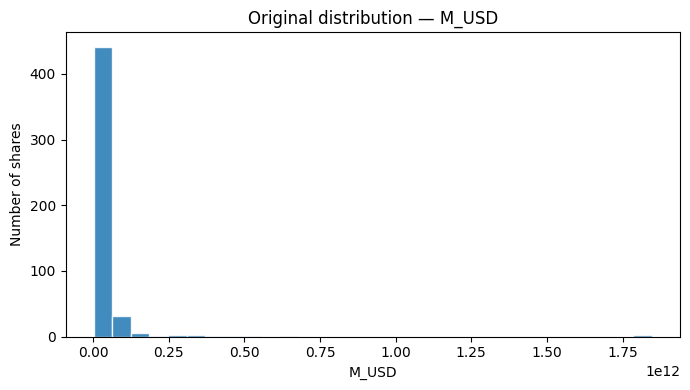

In [97]:
# Task 2.1 - Inspect original feature skew, IQR outlier flags and distributions.
diagnostic_rows=[]
for field in ['MeanWeeklyReturn','WeeklyBeta','R','F','M_USD']:
    v=shares[field]
    q1,q3=v.quantile([0.25,0.75]); iqr=q3-q1
    outlier_count=int(((v<q1-1.5*iqr)|(v>q3+1.5*iqr)).sum())
    diagnostic_rows.append({'Feature':field,'Skewness':v.skew(), 'Minimum':v.min(),
                            'Median':v.median(),'Maximum':v.max(),'IQR_Flagged':outlier_count})
diagnostics=pd.DataFrame(diagnostic_rows)
diagnostics.to_csv(OUT/'feature_skew_outlier_audit.csv', index=False)
display(diagnostics.round(3))
for field in ['MeanWeeklyReturn','WeeklyBeta','R','F','M_USD']:
    fig,ax=plt.subplots(figsize=(7,4))
    ax.hist(shares[field],bins=30,edgecolor='white',alpha=.85)
    ax.set_title(f'Original distribution — {field}');ax.set_xlabel(field);ax.set_ylabel('Number of shares')
    fig.tight_layout();fig.savefig(OUT/f'distribution_{field}.png',dpi=150);plt.show();plt.close(fig)

In [98]:
# Task 2.1 - Required log1p(M) + standardisation; optional skew treatment for R.
LOG_RECENCY = True
risk_input = features_risk_raw.copy()
rfm_input = pd.DataFrame(index=shares.index)
rfm_input['R_model'] = np.log1p(shares['R']) if LOG_RECENCY else shares['R']
rfm_input['F_model'] = shares['F']
rfm_input['log1p_M'] = np.log1p(shares['M_USD'])
scaler_risk = StandardScaler()
scaler_rfm = StandardScaler()
X_risk = pd.DataFrame(scaler_risk.fit_transform(risk_input), columns=risk_input.columns, index=shares.index)
X_rfm = pd.DataFrame(scaler_rfm.fit_transform(rfm_input), columns=rfm_input.columns, index=shares.index)
assert np.isfinite(X_risk.to_numpy()).all() and np.isfinite(X_rfm.to_numpy()).all()
assert (X_risk.std(ddof=0)>0).all() and (X_rfm.std(ddof=0)>0).all()
X_risk.assign(Ticker=shares['Ticker']).to_csv(OUT/'risk_standardised_features.csv',index=False)
X_rfm.assign(Ticker=shares['Ticker']).to_csv(OUT/'rfm_standardised_features.csv',index=False)
with open(OUT/'transformations.json','w') as f:
    json.dump({'R':'log1p(R)' if LOG_RECENCY else 'raw R', 'F':'raw F', 'M':'log1p(M_USD)',
               'risk':['raw mean weekly return','raw weekly beta'],
               'scaling':'StandardScaler fitted separately on each matrix',
               'winsorisation':'none','sample_size':len(shares)},f,indent=2)
print('Risk matrix:',X_risk.shape,'| RFM matrix:',X_rfm.shape, '| LOG_RECENCY:',LOG_RECENCY)

Risk matrix: (489, 2) | RFM matrix: (489, 3) | LOG_RECENCY: True


In [99]:
# Tasks 2.2 & 2.3 - Fit 4 model families across k=2..8 and record objective evidence.
K_VALUES = list(range(2,9))
MIN_CLUSTER_SIZE = max(5, int(math.ceil(len(shares) * 0.02)))  # Minimum 2% (>=5) for interpretable segments.
N_INIT = 30  # Multiple initialisations for K-Means.

def evaluate_models(X, feature_set):
    rows=[]
    fit_lookup={}
    for algorithm in ['Ward','KMeans']:
        for k in K_VALUES:
            if algorithm=='Ward':
                model=AgglomerativeClustering(n_clusters=k, linkage='ward', metric='euclidean')
            else:
                model=KMeans(n_clusters=k, n_init=N_INIT, random_state=SEED, max_iter=500)
            labels=model.fit_predict(X)
            counts=pd.Series(labels).value_counts().sort_index()
            silhouette=float(silhouette_score(X,labels))
            # WCSS is computed for both algorithms to make the objective scale comparable.
            mu=pd.DataFrame(X.to_numpy()).groupby(labels).mean()
            wcss=float(sum(np.sum((X.to_numpy()[labels==cluster]-mu.loc[cluster].to_numpy())**2)
                           for cluster in counts.index))
            rows.append({'FeatureSet':feature_set,'Algorithm':algorithm,'k':k,
                         'Silhouette':silhouette,'WCSS':wcss,
                         'Inertia_KMeans':float(model.inertia_) if algorithm=='KMeans' else np.nan,
                         'MinimumClusterSize':int(counts.min()),'MaximumClusterSize':int(counts.max()),
                         'ClusterSizes':'; '.join(f'{int(key)}:{int(value)}' for key,value in counts.items()),
                         'SizeRulePass':bool(counts.min()>=MIN_CLUSTER_SIZE)})
            fit_lookup[(feature_set,algorithm,k)]={'labels':labels,'model':model}
    return pd.DataFrame(rows),fit_lookup

scores_risk, fits_risk = evaluate_models(X_risk,'RiskReturn')
scores_rfm, fits_rfm = evaluate_models(X_rfm,'RFM')
scores = pd.concat([scores_risk,scores_rfm],ignore_index=True)
scores.to_csv(OUT/'model_k2_to_k8_diagnostics.csv',index=False)
print('Minimum cluster-size rule:',MIN_CLUSTER_SIZE,'shares')
display(scores.round(4))

Minimum cluster-size rule: 10 shares


,FeatureSet,Algorithm,k,Silhouette,WCSS,Inertia_KMeans,MinimumClusterSize,MaximumClusterSize,ClusterSizes,SizeRulePass
0,RiskReturn,Ward,2,0.2880,670.5126,NaN,230,259,0:259; 1:230,True
1,RiskReturn,Ward,3,0.2788,534.1427,NaN,36,230,0:223; 1:230; 2:36,True
2,RiskReturn,Ward,4,0.2907,418.3911,NaN,36,230,0:230; 1:175; 2:36; 3:48,True
3,RiskReturn,Ward,5,0.3120,330.7288,NaN,36,175,0:36; 1:175; 2:131; 3:48; 4:99,True
4,RiskReturn,Ward,6,0.3121,287.9617,NaN,5,175,0:175; 1:99; 2:131; 3:48; 4:5; 5:31,False
5,RiskReturn,Ward,7,0.2919,258.2246,NaN,5,141,0:131; 1:99; 2:141; 3:48; 4:5; 5:31; 6:34,False
6,RiskReturn,Ward,8,0.2794,231.6244,NaN,5,141,0:141; 1:99; 2:109; 3:48; 4:5; 5:31; 6:34; 7:22,False
7,RiskReturn,KMeans,2,0.3858,626.8624,626.8624,144,345,0:345; 1:144,True
8,RiskReturn,KMeans,3,0.3273,465.6085,465.6085,120,203,0:203; 1:166; 2:120,True
9,RiskReturn,KMeans,4,0.3259,374.5057,374.5057,41,162,0:132; 1:154; 2:162; 3:41,True


In [100]:
# Tasks 2.2 & 2.3 - Select k separately for each of the four baseline solutions.
def choose_k(table, feature_set, algorithm):
    t=table[(table.FeatureSet==feature_set)&(table.Algorithm==algorithm)]
    eligible=t.loc[t.SizeRulePass]
    fall_back=eligible.empty
    pool=t if fall_back else eligible
    selection=pool.sort_values(['Silhouette','k'],ascending=[False,True]).iloc[0]
    return {'FeatureSet':feature_set,'Algorithm':algorithm,'SelectedK':int(selection.k),
            'Silhouette':float(selection.Silhouette),'MinimumClusterSize':int(selection.MinimumClusterSize),
            'FallbackUsed':bool(fall_back)}
selected = pd.DataFrame([choose_k(scores, feature_set, algorithm)
                         for feature_set in ['RiskReturn','RFM'] for algorithm in ['Ward','KMeans']])
selected.to_csv(OUT/'selected_cluster_counts.csv',index=False)
display(selected.round(4))

def selected_k(feature_set, algorithm):
    return int(selected[(selected.FeatureSet==feature_set)&(selected.Algorithm==algorithm)].SelectedK.iloc[0])

,FeatureSet,Algorithm,SelectedK,Silhouette,MinimumClusterSize,FallbackUsed
0,RiskReturn,Ward,5,0.3120,36,False
1,RiskReturn,KMeans,2,0.3858,144,False
2,RFM,Ward,2,0.4030,96,False
3,RFM,KMeans,2,0.4157,102,False


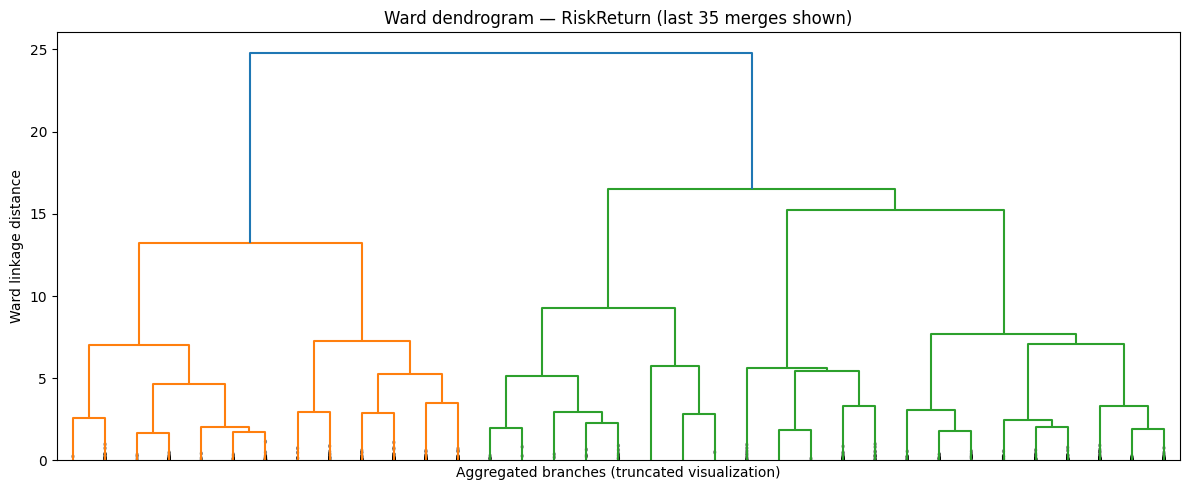

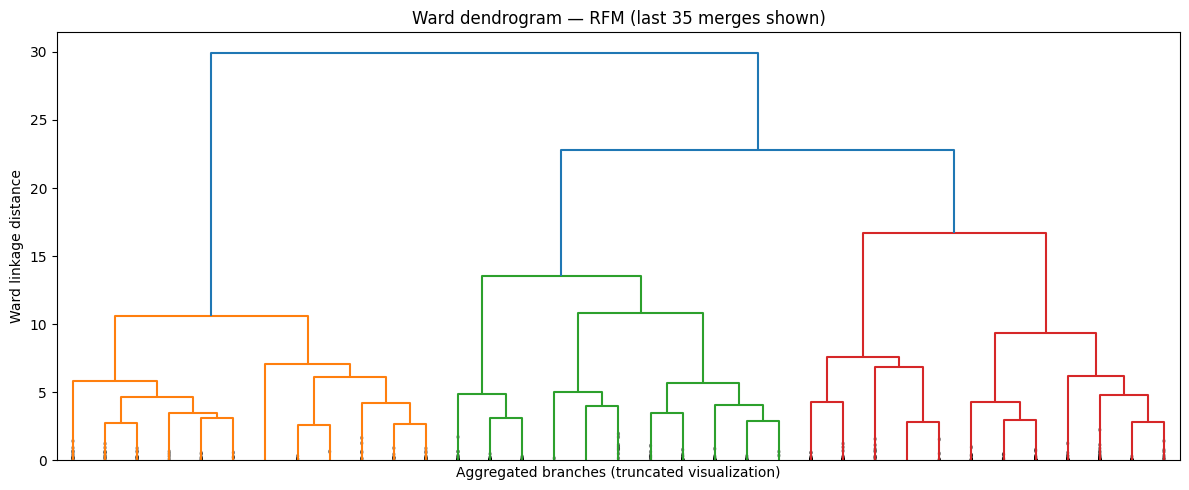

In [101]:
# Task 2.2 - Two dendrograms (one per feature matrix). Truncated for readability.
for name, X in [('RiskReturn',X_risk),('RFM',X_rfm)]:
    Z=linkage(X.to_numpy(),method='ward',metric='euclidean')
    fig,ax=plt.subplots(figsize=(12,5))
    dendrogram(Z, truncate_mode='lastp', p=35, no_labels=True,
               show_contracted=True, color_threshold=None, ax=ax)
    ax.set_title(f'Ward dendrogram — {name} (last 35 merges shown)')
    ax.set_ylabel('Ward linkage distance')
    ax.set_xlabel('Aggregated branches (truncated visualization)')
    fig.tight_layout();fig.savefig(OUT/f'dendrogram_{name}.png',dpi=170);plt.show();plt.close(fig)

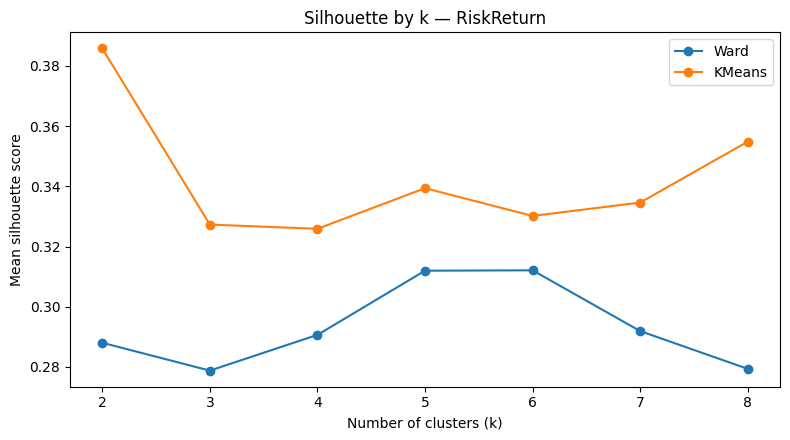

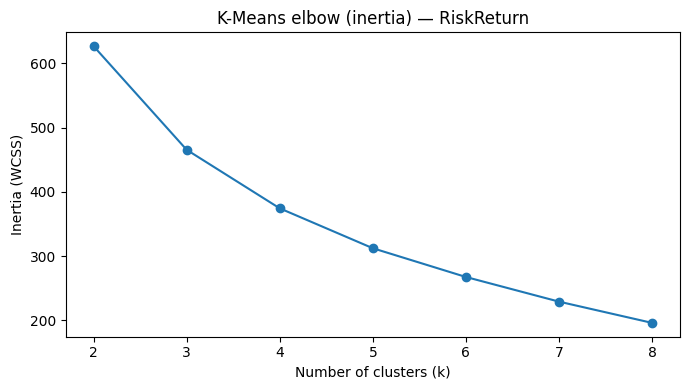

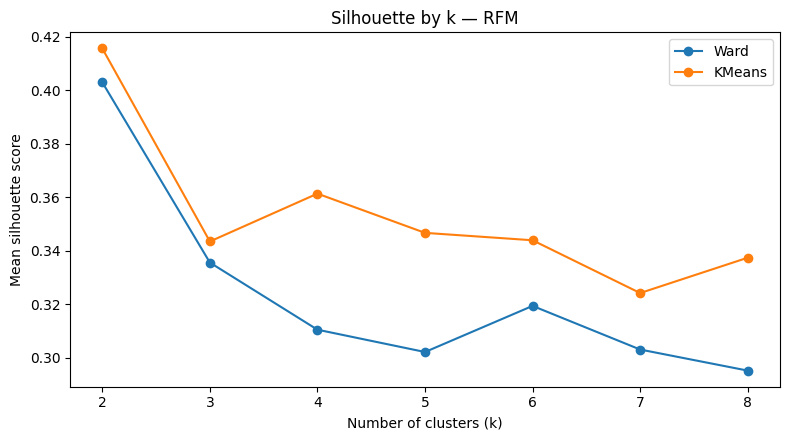

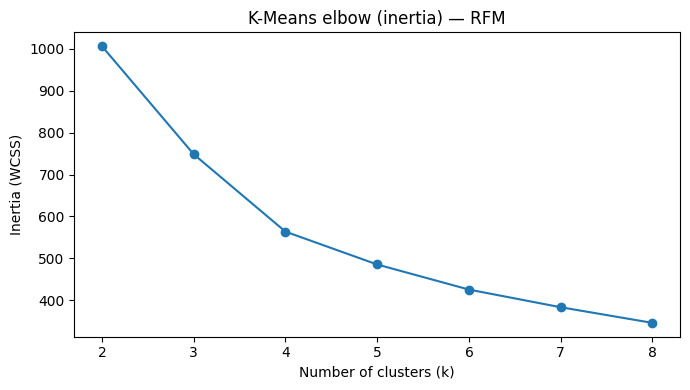

In [102]:
# Tasks 2.2 & 2.3 - Charts for silhouette, K-Means inertia and smallest-cluster size.
for name in ['RiskReturn','RFM']:
    sub=scores[scores.FeatureSet==name]
    fig,ax=plt.subplots(figsize=(8,4.5))
    for method in ['Ward','KMeans']:
        t=sub[sub.Algorithm==method]
        ax.plot(t.k,t.Silhouette,marker='o',label=method)
    ax.set(title=f'Silhouette by k — {name}',xlabel='Number of clusters (k)',ylabel='Mean silhouette score')
    ax.set_xticks(K_VALUES);ax.legend();fig.tight_layout();fig.savefig(OUT/f'silhouette_by_k_{name}.png',dpi=160)
    plt.show();plt.close(fig)
    t=sub[sub.Algorithm=='KMeans']
    fig,ax=plt.subplots(figsize=(7,4))
    ax.plot(t.k,t.Inertia_KMeans,marker='o')
    ax.set(title=f'K-Means elbow (inertia) — {name}',xlabel='Number of clusters (k)',ylabel='Inertia (WCSS)')
    ax.set_xticks(K_VALUES);fig.tight_layout();fig.savefig(OUT/f'kmeans_elbow_{name}.png',dpi=160)
    plt.show();plt.close(fig)

In [103]:
# Task 2.4 - Four baseline solutions using their own selected k; same share population.
colspecs = [('RiskReturn','Ward','Ward_Risk'),('RiskReturn','KMeans','KMeans_Risk'),
            ('RFM','Ward','Ward_RFM'),('RFM','KMeans','KMeans_RFM')]
all_fits={**fits_risk,**fits_rfm}
assigned=shares.copy()
for feat, alg, col in colspecs:
    k=selected_k(feat,alg)
    assigned[col]=all_fits[(feat,alg,k)]['labels'].astype(int)
assigned.to_csv(OUT/'four_baseline_cluster_assignments.csv',index=False)
assert all(assigned[c].notna().all() for _,_,c in colspecs)
print('Final assignments:')
display(assigned[['Ticker','GICS Sector','MeanWeeklyReturn','WeeklyBeta','R','F','M_USD']+
                 [col for _,_,col in colspecs]].head(12))

Final assignments:


,Ticker,GICS Sector,MeanWeeklyReturn,WeeklyBeta,R,F,M_USD,Ward_Risk,KMeans_Risk,Ward_RFM,KMeans_RFM
0,A,Health Care,0.001121,1.074725,11.0,2.0,1.400180e+10,2,0,0,1
1,AAPL,Information Technology,0.003930,1.174835,11.0,2.0,6.233034e+11,1,1,0,1
2,ABBV,Health Care,0.003749,0.425366,11.0,3.0,6.837054e+10,4,0,0,1
3,ABNB,Consumer Discretionary,0.001475,1.472709,11.0,3.0,3.652850e+10,3,1,0,1
4,ABT,Health Care,0.000971,0.583543,11.0,1.0,3.523027e+10,4,0,0,1
5,ACGL,Financials,0.005289,0.586638,11.0,4.0,1.196213e+10,1,0,0,1
6,ACN,Information Technology,0.002376,1.143299,11.0,2.0,5.199430e+10,1,0,0,1
7,ADBE,Information Technology,0.000990,1.553525,18.0,3.0,1.030403e+11,3,1,0,1
8,ADI,Information Technology,0.002610,1.131969,36.0,1.0,3.849918e+10,1,0,1,0
9,ADM,Consumer Staples,0.001048,0.548876,11.0,3.0,9.529780e+09,4,0,0,1


In [104]:
# Task 2.4 - Original-unit profiles: means/medians, activity in USD billions, returns in percent.
def make_profile(df, assignment_col):
    grouped=df.groupby(assignment_col,sort=True)
    profile=grouped.agg(N=('Ticker','size'),
                        MeanWeeklyReturnPct=('MeanWeeklyReturn',lambda x:100*x.mean()),
                        MedianWeeklyReturnPct=('MeanWeeklyReturn',lambda x:100*x.median()),
                        MeanWeeklyBeta=('WeeklyBeta','mean'), MedianWeeklyBeta=('WeeklyBeta','median'),
                        MeanRecencyDays=('R','mean'), MedianRecencyDays=('R','median'),
                        MeanFrequencyDays=('F','mean'), MedianFrequencyDays=('F','median'),
                        MeanTradedValueUSDbn=('M_USD',lambda x:x.mean()/1e9),
                        MedianTradedValueUSDbn=('M_USD',lambda x:x.median()/1e9))
    profile['SharePct'] = 100*profile.N/len(df)
    profile=profile.reset_index().rename(columns={assignment_col:'Cluster'})
    profile.insert(0,'Solution',assignment_col)
    return profile
profiles=pd.concat([make_profile(assigned,c) for _,_,c in colspecs],ignore_index=True)
profiles.to_csv(OUT/'four_baseline_cluster_profiles_original_units.csv',index=False)
display(profiles.round(3))

,Solution,Cluster,N,MeanWeeklyReturnPct,MedianWeeklyReturnPct,MeanWeeklyBeta,MedianWeeklyBeta,MeanRecencyDays,MedianRecencyDays,MeanFrequencyDays,MedianFrequencyDays,MeanTradedValueUSDbn,MedianTradedValueUSDbn,SharePct
0,Ward_Risk,0,36,0.882,0.793,1.434,1.402,26.611,11.0,3.250,3.0,102.414,25.488,7.362
1,Ward_Risk,1,175,0.409,0.408,0.993,0.993,18.366,11.0,2.823,3.0,36.852,18.250,35.787
2,Ward_Risk,2,131,0.076,0.107,0.958,0.934,17.870,11.0,3.076,3.0,18.811,12.891,26.789
3,Ward_Risk,3,48,0.200,0.252,1.628,1.514,23.542,11.0,3.229,3.0,86.935,28.698,9.816
4,Ward_Risk,4,99,0.173,0.188,0.475,0.474,23.414,11.0,2.949,3.0,24.452,17.132,20.245
5,KMeans_Risk,0,345,0.183,0.192,0.818,0.841,19.458,11.0,2.922,3.0,21.838,14.206,70.552
6,KMeans_Risk,1,144,0.534,0.487,1.347,1.275,22.556,11.0,3.146,3.0,80.970,25.375,29.448
7,Ward_RFM,0,393,0.285,0.268,0.965,0.935,12.087,11.0,3.206,3.0,37.836,15.335,80.368
8,Ward_RFM,1,96,0.294,0.257,1.011,1.031,54.281,53.0,2.094,2.0,45.043,21.147,19.632
9,KMeans_RFM,0,102,0.314,0.263,1.061,1.063,53.667,49.0,2.294,2.0,64.474,21.183,20.859


RFM PCA explained variance (first two components): 77.26 %


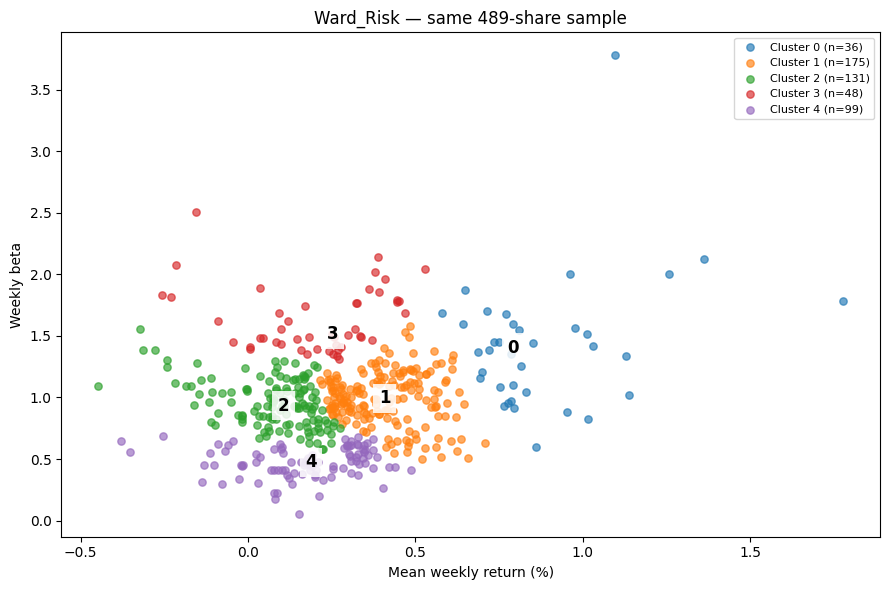

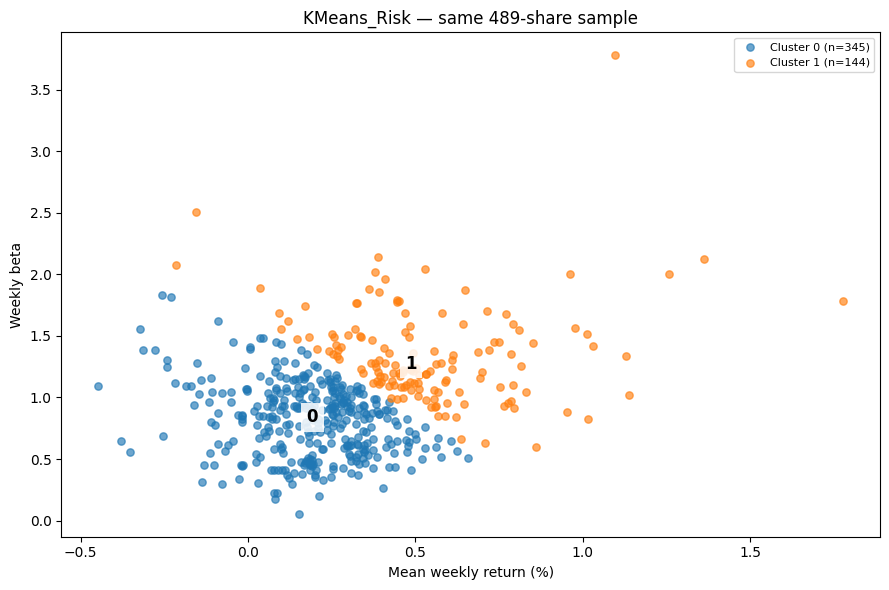

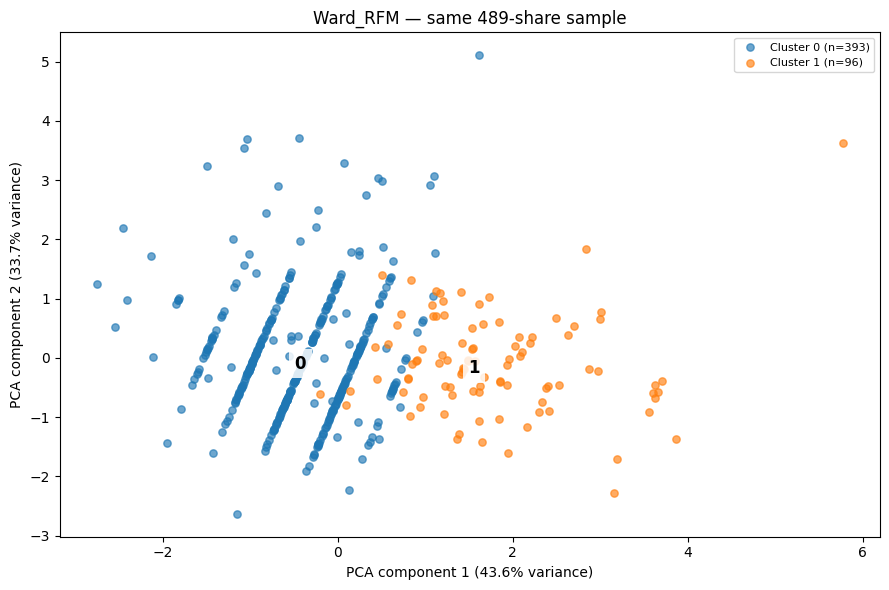

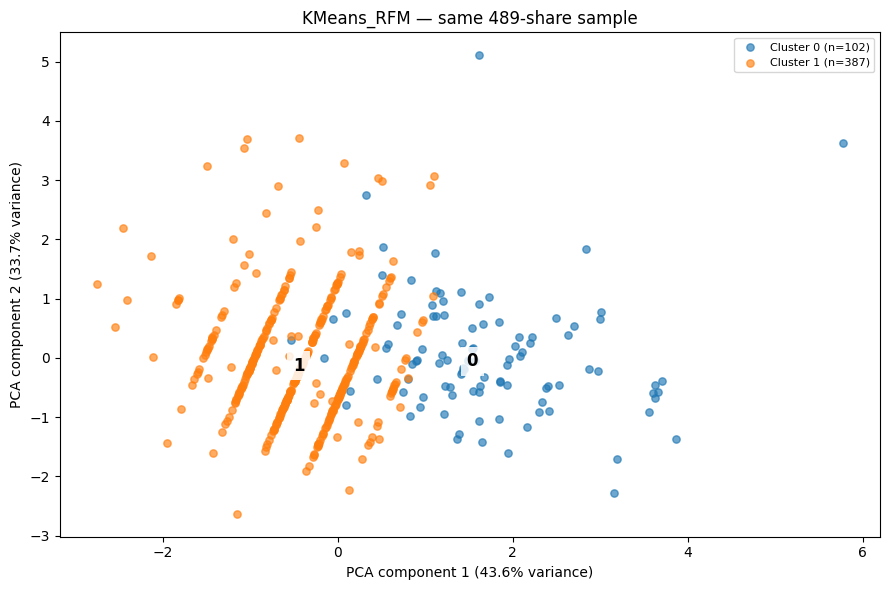

In [105]:
# Task 2.4 - 2D views: raw risk-return axes; RFM uses PCA of scaled 3D features.
pca=PCA(n_components=2,random_state=SEED)
rfm_xy=pca.fit_transform(X_rfm)
pca_info={'PC1_explained_pct':100*float(pca.explained_variance_ratio_[0]),
          'PC2_explained_pct':100*float(pca.explained_variance_ratio_[1]),
          'Total_explained_pct':100*float(pca.explained_variance_ratio_.sum()),
          'loadings':{str(col):[float(v) for v in vec] for col,vec in zip(X_rfm.columns,pca.components_.T)}}
with open(OUT/'rfm_pca_explained_variance.json','w') as f:json.dump(pca_info,f,indent=2)
print('RFM PCA explained variance (first two components):', round(pca_info['Total_explained_pct'],2),'%')

def plot_solution(col, risk):
    labels=assigned[col].to_numpy()
    x=100*shares['MeanWeeklyReturn'].to_numpy() if risk else rfm_xy[:,0]
    y=shares['WeeklyBeta'].to_numpy() if risk else rfm_xy[:,1]
    fig,ax=plt.subplots(figsize=(9,6))
    unique=np.sort(np.unique(labels))
    cmap=plt.get_cmap('tab10')
    for i,cl in enumerate(unique):
        sel=labels==cl
        ax.scatter(x[sel],y[sel],s=28,alpha=.65,color=cmap(i%10),label=f'Cluster {cl} (n={sel.sum()})')
        ax.text(np.median(x[sel]),np.median(y[sel]),str(cl),fontsize=12,fontweight='bold',
                ha='center',va='center',bbox={'facecolor':'white','alpha':.85,'edgecolor':'none'})
    ax.set_title(f'{col} — same 489-share sample' if len(shares)==489 else f'{col} — {len(shares)} shares')
    ax.set_xlabel('Mean weekly return (%)' if risk else f'PCA component 1 ({pca_info["PC1_explained_pct"]:.1f}% variance)')
    ax.set_ylabel('Weekly beta' if risk else f'PCA component 2 ({pca_info["PC2_explained_pct"]:.1f}% variance)')
    ax.legend(loc='best',fontsize=8);fig.tight_layout()
    fig.savefig(OUT/f'scatter_{col}.png',dpi=165);plt.show();plt.close(fig)
for feat,alg,col in colspecs: plot_solution(col,risk=feat=='RiskReturn')

In [106]:
# Task 2.4 - Algorithm comparisons with ARI (cluster numbers have no fixed meaning).
comparison_rows=[]
for a,b in [('Ward_Risk','KMeans_Risk'),('Ward_RFM','KMeans_RFM'),
            ('Ward_Risk','Ward_RFM'),('KMeans_Risk','KMeans_RFM')]:
    score=float(adjusted_rand_score(assigned[a],assigned[b]))
    comparison_rows.append({'Solution1':a,'Solution2':b,'AdjustedRandIndex':score})
    pd.crosstab(assigned[a],assigned[b]).to_csv(OUT/f'cross_tab_{a}_vs_{b}.csv')
comparison=pd.DataFrame(comparison_rows)
comparison.to_csv(OUT/'baseline_algorithm_comparisons_ARI.csv',index=False)
display(comparison.round(4))

,Solution1,Solution2,AdjustedRandIndex
0,Ward_Risk,KMeans_Risk,0.1483
1,Ward_RFM,KMeans_RFM,0.8904
2,Ward_Risk,Ward_RFM,0.0062
3,KMeans_Risk,KMeans_RFM,0.0365


,R,F,log1p(M)
R,1.0000,-0.3461,0.1531
F,-0.3461,1.0000,0.0128
log1p(M),0.1531,0.0128,1.0000


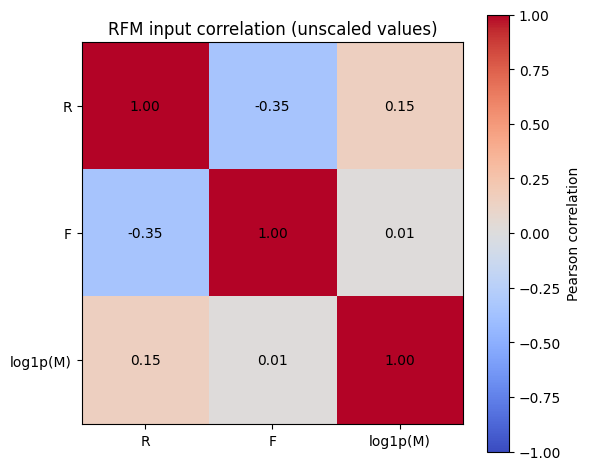

Correlation can indicate repeated distance influence; it does NOT prove feature dominance.


In [107]:
# Task 2.5.1 - Correlation required on original R/F and log1p(M), not scaled data.
corr_frame=pd.DataFrame({'R':shares['R'], 'F':shares['F'], 'log1p(M)':np.log1p(shares['M_USD'])})
rfm_corr=corr_frame.corr(method='pearson')
rfm_corr.to_csv(OUT/'rfm_correlation_pearson.csv')
display(rfm_corr.round(4))
fig,ax=plt.subplots(figsize=(6,5))
image=ax.imshow(rfm_corr.values,cmap='coolwarm',vmin=-1,vmax=1)
ax.set_xticks(range(3),rfm_corr.columns);ax.set_yticks(range(3),rfm_corr.index)
for i in range(3):
    for j in range(3):
        ax.text(j,i,f'{rfm_corr.iloc[i,j]:.2f}',ha='center',va='center',color='black')
fig.colorbar(image,ax=ax,label='Pearson correlation')
ax.set_title('RFM input correlation (unscaled values)')
fig.tight_layout();fig.savefig(OUT/'rfm_correlation_heatmap.png',dpi=160);plt.show();plt.close(fig)
print('Correlation can indicate repeated distance influence; it does NOT prove feature dominance.')

In [108]:
# Task 2.5.2 - Refitting Ward using R and F only; same shares and selected Ward RFM k.
rf_input = rfm_input[['R_model','F_model']].copy()  # Uses the SAME Recency transformation.
X_rf = pd.DataFrame(StandardScaler().fit_transform(rf_input),columns=rf_input.columns,index=shares.index)
fixed_k = selected_k('RFM','Ward')
rf_labels = AgglomerativeClustering(n_clusters=fixed_k,linkage='ward',metric='euclidean').fit_predict(X_rf)
assigned['Ward_RF_Without_M'] = rf_labels.astype(int)
ari_remove_M = float(adjusted_rand_score(assigned['Ward_RFM'],assigned['Ward_RF_Without_M']))
rf_stability = pd.crosstab(assigned['Ward_RFM'],assigned['Ward_RF_Without_M'])
rf_stability.to_csv(OUT/'rfm_vs_rf_Ward_membership_crosstab.csv')
rf_profiles = pd.concat([make_profile(assigned,'Ward_RFM'),make_profile(assigned,'Ward_RF_Without_M')],ignore_index=True)
rf_profiles.to_csv(OUT/'monetary_removal_original_unit_profiles.csv',index=False)
assigned[['Ticker','GICS Sector','R','F','M_USD','Ward_RFM','Ward_RF_Without_M']].to_csv(OUT/'monetary_removal_membership_comparison.csv',index=False)
with open(OUT/'monetary_removal_summary.json','w') as f:
    json.dump({'baseline':'Ward_RFM','reduced':'Ward_RF_Without_M','k_fixed':fixed_k,
               'same_shares':len(assigned), 'adjusted_rand_index':ari_remove_M,
               'recency_transform':'log1p' if LOG_RECENCY else 'none',
               'scaler':'refitted StandardScaler on R and F'},f,indent=2)
print('Ward RFM fixed k:',fixed_k, '| Ward R/F only ARI:',round(ari_remove_M,4))
display(rf_stability)
display(rf_profiles.round(2))

Ward RFM fixed k: 2 | Ward R/F only ARI: 0.7896


Ward_RF_Without_M,0,1
Ward_RFM,,
0,374,19
1,5,91


,Solution,Cluster,N,MeanWeeklyReturnPct,MedianWeeklyReturnPct,MeanWeeklyBeta,MedianWeeklyBeta,MeanRecencyDays,MedianRecencyDays,MeanFrequencyDays,MedianFrequencyDays,MeanTradedValueUSDbn,MedianTradedValueUSDbn,SharePct
0,Ward_RFM,0,393,0.28,0.27,0.96,0.93,12.09,11.0,3.21,3.0,37.84,15.33,80.37
1,Ward_RFM,1,96,0.29,0.26,1.01,1.03,54.28,53.0,2.09,2.0,45.04,21.15,19.63
2,Ward_RF_Without_M,0,379,0.28,0.26,0.95,0.93,11.35,11.0,3.12,3.0,31.34,15.32,77.51
3,Ward_RF_Without_M,1,110,0.32,0.27,1.07,1.07,51.44,46.0,2.53,2.0,66.50,20.49,22.49


In [109]:
# Task 2 - Final QA and reproducibility metadata.
assert len(assigned)==len(shares)==len(X_risk)==len(X_rfm)==len(X_rf)
assert assigned['Ticker'].is_unique
for feature_set,algorithm,column in colspecs:
    assert assigned[column].notna().all()
    assert assigned[column].nunique()==selected_k(feature_set,algorithm)
assert assigned['Ward_RF_Without_M'].nunique()==fixed_k
assert np.isfinite(profiles.select_dtypes(include='number').to_numpy()).all()
assert np.allclose(rfm_corr.values,rfm_corr.values.T)
assert np.allclose(X_risk.mean(),0,atol=1e-12)
assert np.allclose(X_rfm.mean(),0,atol=1e-12)
assert np.allclose(X_rf.mean(),0,atol=1e-12)
assert -1.0 <= ari_remove_M <= 1.0
required_files = ['four_baseline_cluster_assignments.csv','selected_cluster_counts.csv',
                  'four_baseline_cluster_profiles_original_units.csv','model_k2_to_k8_diagnostics.csv',
                  'rfm_correlation_pearson.csv','monetary_removal_summary.json',
                  'rfm_pca_explained_variance.json','transformations.json',
                  'dendrogram_RFM.png','dendrogram_RiskReturn.png']
missing=[f for f in required_files if not (OUT/f).is_file()]
assert not missing, f'Missing Task 2 outputs: {missing}'
manifest={'created_utc':datetime.now(timezone.utc).isoformat(),
          'source_zip':INPUT_ZIP.name,'source_retrieval':retrieval_metadata.get('retrieved_utc'),
          'task1_metadata':task1_metadata,'python_version':platform.python_version(),
          'pandas_version':pd.__version__,'numpy_version':np.__version__,
          'sklearn_version':sklearn.__version__,'scipy_version':scipy.__version__,
          'random_seed':SEED,'k_candidates':K_VALUES,'minimum_cluster_size':MIN_CLUSTER_SIZE,
          'kmeans_n_init':N_INIT,'log_recency':LOG_RECENCY,'share_count':len(shares),
          'selected_cluster_counts':selected.to_dict(orient='records'),
          'ari_removing_monetary':ari_remove_M,
          'pca_explained_pct':pca_info['Total_explained_pct'],
          'warning':'Descriptive clusters only; future returns and diversification have not been tested'}
(OUT/'task2_analysis_provenance.json').write_text(json.dumps(manifest,indent=2),encoding='utf-8')
print('PASS: Task 2 verified. Common shares:',len(shares),'| Output files:',len(list(OUT.iterdir())))
display(selected.round(4))

PASS: Task 2 verified. Common shares: 489 | Output files: 38


,FeatureSet,Algorithm,SelectedK,Silhouette,MinimumClusterSize,FallbackUsed
0,RiskReturn,Ward,5,0.3120,36,False
1,RiskReturn,KMeans,2,0.3858,144,False
2,RFM,Ward,2,0.4030,96,False
3,RFM,KMeans,2,0.4157,102,False


In [110]:
# Task 2 - Create a ZIP to download, and use it as Task 3 input.
archive_path = Path(shutil.make_archive(str(ROOT/'task2_outputs'),'zip',root_dir=OUT))
print('Task 2 ZIP created:', archive_path, '| size:',round(archive_path.stat().st_size/1024/1024,2),'MB')

Task 2 ZIP created: /content/task2_outputs.zip | size: 0.98 MB


In [111]:
# Download Task 2 analysis results

from google.colab import files

files.download('/content/task2_outputs.zip')

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

In [112]:
#Task 03: Business Intelligence and Critical Review

In [113]:
# Task 3 - Upload/read Task 2 results ZIP and restore the analytical summaries.
required = {'four_baseline_cluster_assignments.csv',
            'selected_cluster_counts.csv',
            'baseline_algorithm_comparisons_ARI.csv',
            'rfm_correlation_pearson.csv',
            'monetary_removal_summary.json',
            'transformations.json',
            'rfm_pca_explained_variance.json'}
options = [ROOT/'task2_outputs.zip',ROOT/'task2_task3_outputs.zip',
           Path('/mnt/data/task2_outputs.zip'), Path('/mnt/data/task2_task3_outputs(1).zip')]
found = next((p for p in options if p.is_file()), None)
if found is None:
    try:
        from google.colab import files
        print('Please upload task2_outputs.zip (from the separate Task 2 notebook).')
        uploaded=files.upload()
        if not uploaded: raise FileNotFoundError('No ZIP uploaded.')
        found=ROOT/next(iter(uploaded))
        if not found.exists(): found=Path.cwd()/next(iter(uploaded))
    except ImportError:
        raise FileNotFoundError('Copy task2_outputs.zip into the current folder, then rerun.')
INPUT_TASK2_ZIP=found
with zipfile.ZipFile(INPUT_TASK2_ZIP) as task2_archive:
    archive_items=set(task2_archive.namelist())
    missing=sorted(required-archive_items)
    if missing: raise ValueError(f'Wrong/incomplete Task 2 ZIP. Missing: {missing}')
    assigned=pd.read_csv(task2_archive.open('four_baseline_cluster_assignments.csv'))
    selected=pd.read_csv(task2_archive.open('selected_cluster_counts.csv'))
    comparison=pd.read_csv(task2_archive.open('baseline_algorithm_comparisons_ARI.csv'))
    rfm_corr=pd.read_csv(task2_archive.open('rfm_correlation_pearson.csv'),index_col=0)
    sensitivity=json.loads(task2_archive.read('monetary_removal_summary.json').decode('utf-8'))
    transforms=json.loads(task2_archive.read('transformations.json').decode('utf-8'))
    pca_info=json.loads(task2_archive.read('rfm_pca_explained_variance.json').decode('utf-8'))
    original_profiles=pd.read_csv(task2_archive.open('four_baseline_cluster_profiles_original_units.csv'))
    if 'task2_analysis_provenance.json' in archive_items:
        task2_provenance=json.loads(task2_archive.read('task2_analysis_provenance.json').decode('utf-8'))
    elif 'analysis_provenance.json' in archive_items:
        task2_provenance=json.loads(task2_archive.read('analysis_provenance.json').decode('utf-8'))
    else:
        task2_provenance={}
shares=assigned.copy()
colspecs=[('RiskReturn','Ward','Ward_Risk'),('RiskReturn','KMeans','KMeans_Risk'),
          ('RFM','Ward','Ward_RFM'),('RFM','KMeans','KMeans_RFM')]
LOG_RECENCY=bool(transforms.get('R')=='log1p(R)')
N_INIT=int(task2_provenance.get('kmeans_n_init',30))
fixed_k=int(sensitivity['k_fixed'])
ari_remove_M=float(sensitivity['adjusted_rand_index'])
assert len(shares)>=10 and shares.Ticker.is_unique
assert all(c in shares.columns for _,_,c in colspecs)
print('Task 2 ZIP:',INPUT_TASK2_ZIP.name)
print('Loaded shares:',len(shares),'| sectors:',shares['GICS Sector'].nunique())
print('Selected models:')
display(selected.round(4))

Task 2 ZIP: task2_outputs.zip
Loaded shares: 489 | sectors: 11
Selected models:


,FeatureSet,Algorithm,SelectedK,Silhouette,MinimumClusterSize,FallbackUsed
0,RiskReturn,Ward,5,0.3120,36,False
1,RiskReturn,KMeans,2,0.3858,144,False
2,RFM,Ward,2,0.4030,96,False
3,RFM,KMeans,2,0.4157,102,False


In [114]:
# Task 3.1 - Export logical data-mart specification for the final report / BI diagram.
schema_rows=[
 ('DimDate','date_key','date_key','Calendar attributes: date, day, week-ending Friday, month, quarter, year'),
 ('DimShare','share_key','share_key; sector_key','Ticker, security name, listing metadata; slowly changing attributes if available'),
 ('DimSector','sector_key','sector_key','GICS sector and classification version'),
 ('DimBenchmark','benchmark_key','benchmark_key','^GSPC, price basis and currency metadata'),
 ('DimRun','run_id','run_id','Source URL, retrieval UTC, task1 code version, software, lookbacks, observation date, exclusions'),
 ('DimModel','model_key','model_key','Ward/KMeans, feature set, k, seed, scaler, PCA parameters'),
 ('FactDailyQuote','share_key+date_key+run_id','share_key; date_key; run_id','OHLC, AdjClose, volume, dividends, splits, estimated traded value'),
 ('FactWeeklyReturn','share_key+week_end_date_key+run_id','share_key; week_end_date_key; benchmark_key; run_id','Weekly share and benchmark returns, paired-week flag'),
 ('FactShareFeature','share_key+observation_date_key+run_id','share_key; observation_date_key; run_id','MeanWeeklyReturn, WeeklyBeta, alignedWeeks, R, F, M_USD, high-volume cutoff'),
 ('FactClusterAssignment','share_key+run_id+model_key','share_key; run_id; model_key','Cluster ID, silhouette diagnostics; cluster IDs are not rankings')]
mart_schema=pd.DataFrame(schema_rows,columns=['Entity','Grain_or_PK','Keys','Attributes_or_Measures'])
mart_schema.to_csv(OUT/'proposed_data_mart_schema.csv',index=False)
display(mart_schema)

,Entity,Grain_or_PK,Keys,Attributes_or_Measures
0,DimDate,date_key,date_key,"Calendar attributes: date, day, week-ending Fr..."
1,DimShare,share_key,share_key; sector_key,"Ticker, security name, listing metadata; slowl..."
2,DimSector,sector_key,sector_key,GICS sector and classification version
3,DimBenchmark,benchmark_key,benchmark_key,"^GSPC, price basis and currency metadata"
4,DimRun,run_id,run_id,"Source URL, retrieval UTC, task1 code version,..."
5,DimModel,model_key,model_key,"Ward/KMeans, feature set, k, seed, scaler, PCA..."
6,FactDailyQuote,share_key+date_key+run_id,share_key; date_key; run_id,"OHLC, AdjClose, volume, dividends, splits, est..."
7,FactWeeklyReturn,share_key+week_end_date_key+run_id,share_key; week_end_date_key; benchmark_key; r...,"Weekly share and benchmark returns, paired-wee..."
8,FactShareFeature,share_key+observation_date_key+run_id,share_key; observation_date_key; run_id,"MeanWeeklyReturn, WeeklyBeta, alignedWeeks, R,..."
9,FactClusterAssignment,share_key+run_id+model_key,share_key; run_id; model_key,"Cluster ID, silhouette diagnostics; cluster ID..."


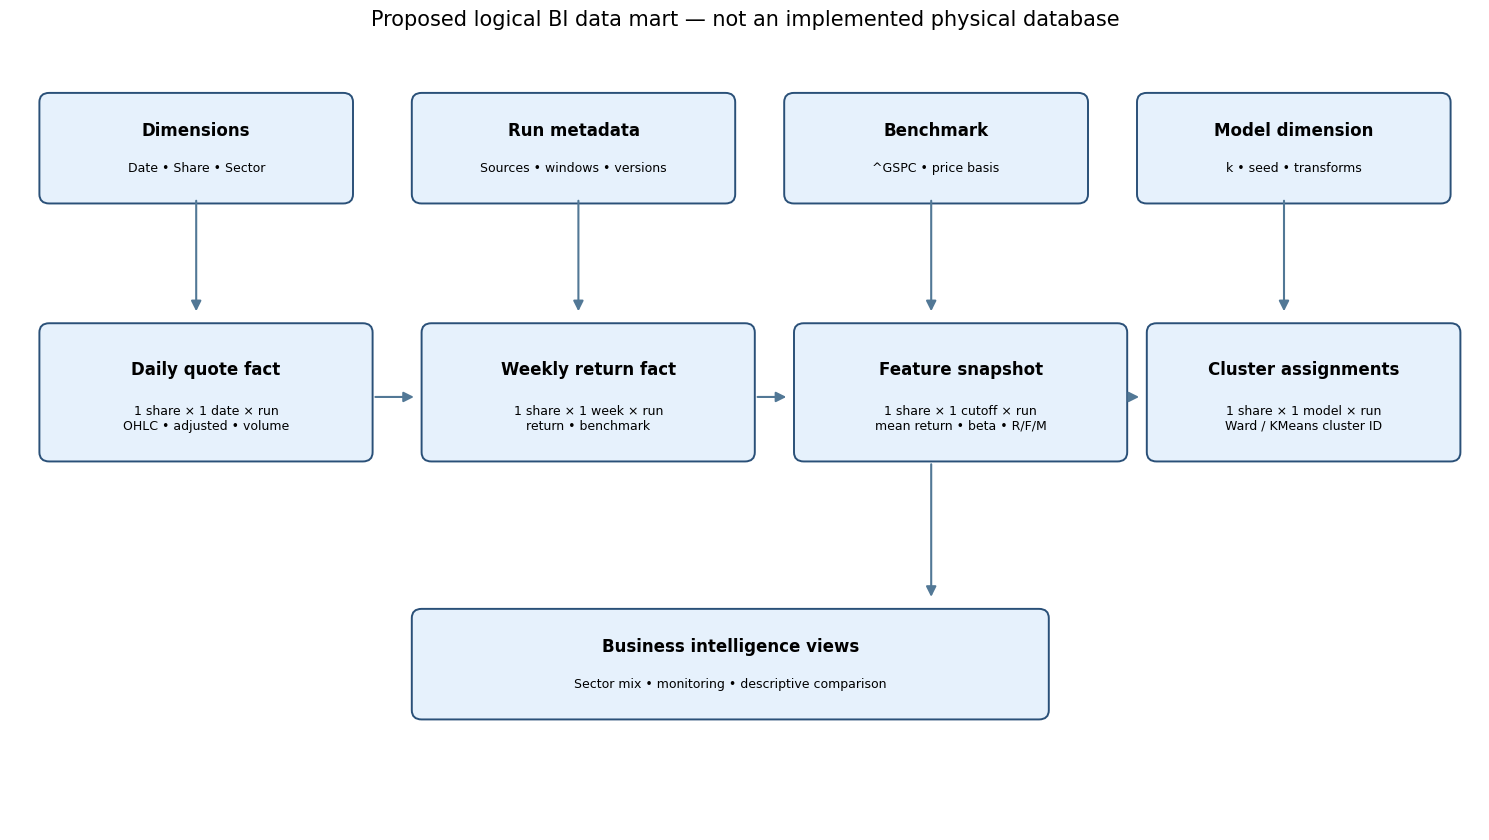

In [115]:
# Task 3.1 - Logical architecture diagram: dimensions, daily/weekly facts, features and clustering facts.
fig,ax=plt.subplots(figsize=(15,8.5));ax.set_xlim(0,15);ax.set_ylim(0,8.5);ax.axis('off')
items=[
 (0.4,6.9,3.0,1.0,'Dimensions','Date • Share • Sector'),
 (4.2,6.9,3.1,1.0,'Run metadata','Sources • windows • versions'),
 (8.0,6.9,2.9,1.0,'Benchmark','^GSPC • price basis'),
 (11.6,6.9,3.0,1.0,'Model dimension','k • seed • transforms'),
 (0.4,4.1,3.2,1.3,'Daily quote fact','1 share × 1 date × run\nOHLC • adjusted • volume'),
 (4.3,4.1,3.2,1.3,'Weekly return fact','1 share × 1 week × run\nreturn • benchmark'),
 (8.1,4.1,3.2,1.3,'Feature snapshot','1 share × 1 cutoff × run\nmean return • beta • R/F/M'),
 (11.7,4.1,3.0,1.3,'Cluster assignments','1 share × 1 model × run\nWard / KMeans cluster ID'),
 (4.2,1.3,6.3,1.0,'Business intelligence views','Sector mix • monitoring • descriptive comparison')]
from matplotlib.patches import FancyBboxPatch, FancyArrowPatch
for x,y,w,h,title,subtitle in items:
    patch=FancyBboxPatch((x,y),w,h,boxstyle='round,pad=0.10',fc='#e6f1fc',ec='#2a5078',lw=1.4)
    ax.add_patch(patch);ax.text(x+w/2,y+h*.69,title,fontsize=12,fontweight='bold',ha='center',va='center')
    ax.text(x+w/2,y+h*.28,subtitle,fontsize=9,ha='center',va='center')
for p,q in [((1.9,6.86),(1.9,5.6)),((5.8,6.86),(5.8,5.6)),((9.4,6.86),(9.4,5.6)),
            ((13,6.86),(13,5.6)),((3.7,4.7),(4.15,4.7)),((7.6,4.7),(7.95,4.7)),
            ((11.4,4.7),(11.55,4.7)),((9.4,4.0),(9.4,2.5))]:
    ax.add_patch(FancyArrowPatch(p,q,arrowstyle='-|>',mutation_scale=15,color='#527896',lw=1.5))
ax.set_title('Proposed logical BI data mart — not an implemented physical database',fontsize=15,pad=15)
fig.tight_layout();fig.savefig(OUT/'proposed_data_mart_diagram.png',dpi=160);plt.show();plt.close(fig)

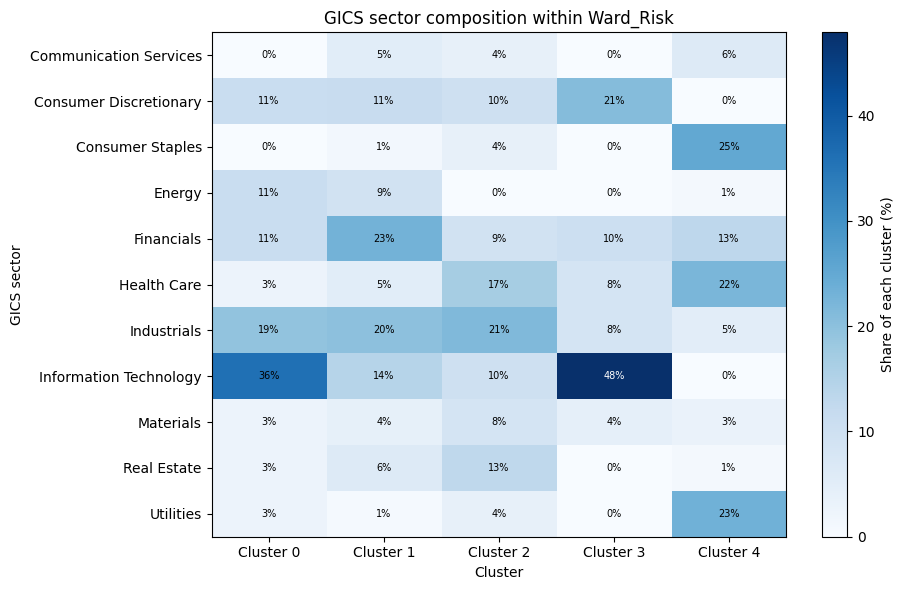

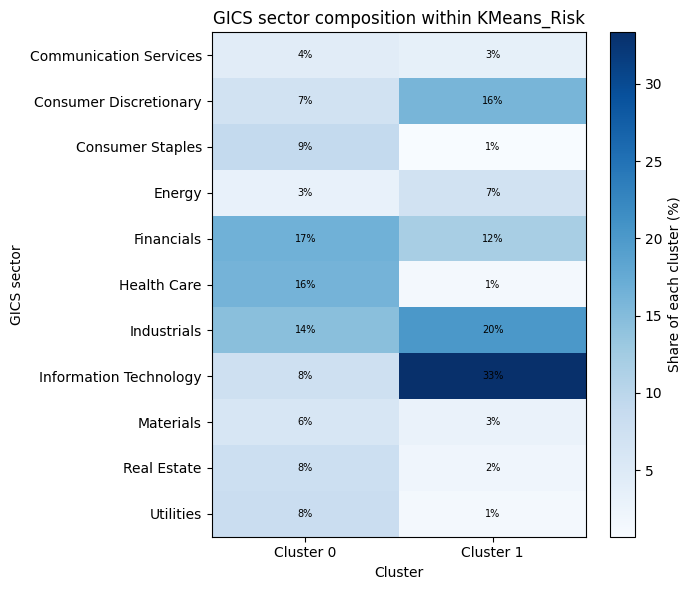

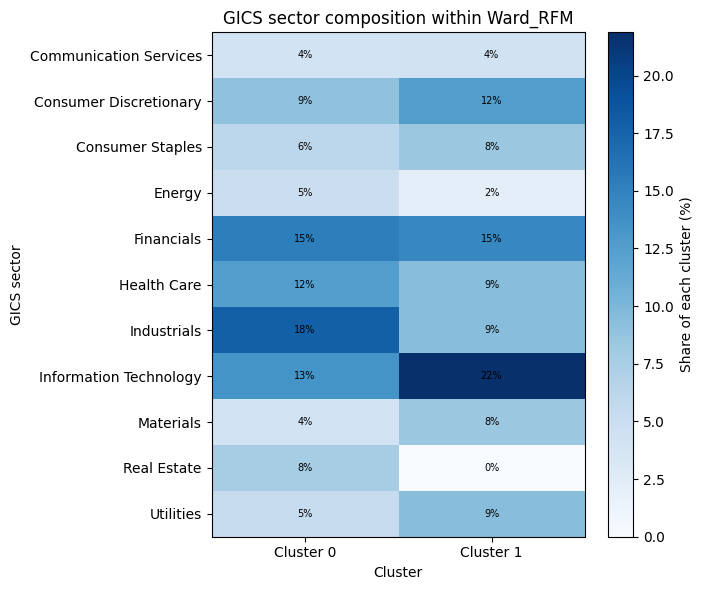

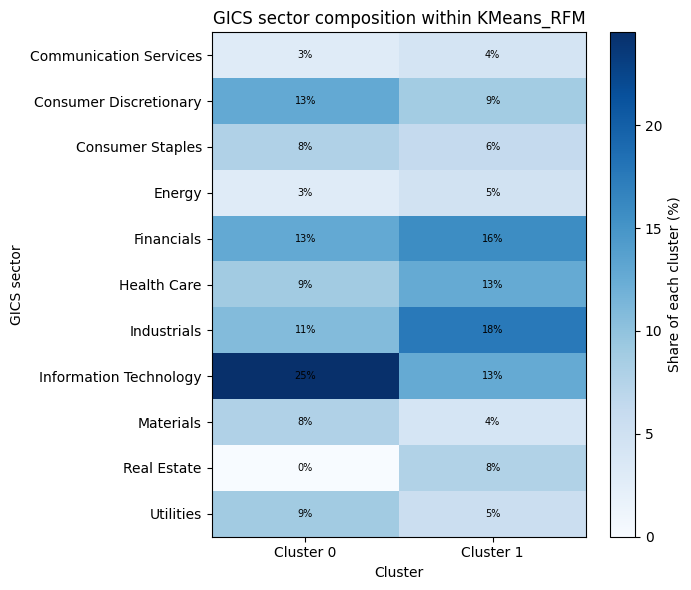

In [116]:
# Task 3.2.1 - Sector composition uses GICS labels for interpretation, not model inputs.
for feat,alg,solution in colspecs:
    counts=pd.crosstab(assigned['GICS Sector'],assigned[solution]).sort_index()
    shares_by_cluster=counts.div(counts.sum(axis=0),axis=1)*100
    counts.to_csv(OUT/f'sector_counts_{solution}.csv')
    shares_by_cluster.to_csv(OUT/f'sector_composition_pct_{solution}.csv')
    fig,ax=plt.subplots(figsize=(max(7,1.3*counts.shape[1]+3),6))
    hm=ax.imshow(shares_by_cluster.to_numpy(),cmap='Blues',aspect='auto')
    ax.set_xticks(range(counts.shape[1]),[f'Cluster {c}' for c in counts.columns])
    ax.set_yticks(range(counts.shape[0]),counts.index)
    ax.set(title=f'GICS sector composition within {solution}',xlabel='Cluster',ylabel='GICS sector')
    for i in range(counts.shape[0]):
        for j in range(counts.shape[1]):
            val=shares_by_cluster.iloc[i,j]
            ax.text(j,i,f'{val:.0f}%',ha='center',va='center',fontsize=7,color='white' if val>40 else 'black')
    fig.colorbar(hm,ax=ax,label='Share of each cluster (%)')
    fig.tight_layout();fig.savefig(OUT/f'sector_composition_{solution}.png',dpi=165);plt.show();plt.close(fig)

In [117]:
# Task 3.2 - Generate a FACTUAL report-evidence sheet (not a finished AI-written submission).
sect_counts=assigned['GICS Sector'].value_counts()
notes=[
'# Tasks 2 and 3 - evidence summary (verify before using in your own report)',
'',f'- Dataset: {len(shares)} shares from {len(sect_counts)} GICS sectors; original observation date 2024-12-31.',
'- Two independent feature matrices: mean weekly return + weekly beta; R + F + log1p(M).',
 f'- Recency transformed using log1p: {LOG_RECENCY}; no winsorisation; all inputs standardised within each matrix.',
 f'- Searched k=2..8; seeded KMeans uses n_init={N_INIT}; Ward uses Euclidean distance and Ward linkage.',
 '', '## Selected k and silhouettes']
for _,row in selected.iterrows():
    notes.append(f'- {row.FeatureSet} {row.Algorithm}: k={int(row.SelectedK)}, silhouette={row.Silhouette:.4f}, minimum cluster size={int(row.MinimumClusterSize)}, fallback={bool(row.FallbackUsed)}')
notes += ['', '## Agreement between solutions (Adjusted Rand Index)']
for _,row in comparison.iterrows():
    notes.append(f'- {row.Solution1} versus {row.Solution2}: ARI={row.AdjustedRandIndex:.4f}')
notes += ['', '## RFM correlation (Pearson; raw R, raw F, log1p M)']
for a,b in [('R','F'),('R','log1p(M)'),('F','log1p(M)')]:
    notes.append(f'- {a} vs {b}: {rfm_corr.loc[a,b]:.4f}')
notes += [f'- Removing Monetary (same shares, same Ward k={fixed_k}, freshly scaled R/F): ARI={ari_remove_M:.4f}',
 '', '## Sector composition and stakeholder use',
 '- Use exported sector-composition plots to describe which sectors are represented in each cluster.',
 '- Risk-return groupings describe historical average weekly performance and index beta; RFM groupings describe volume-event recency/frequency and estimated traded value.',
 '- Use these profiles to monitor activity, investigate unusual changes and support portfolio screening, not to claim diversification or future returns.',
 '', '## Required cautions',
 '- Using 2026 constituents for 2021-2024 introduces survivorship/membership-selection bias.',
 '- Beta is historical systematic sensitivity and does not quantify covariance among all share pairs.',
 '- Adjusted-price series, corporate actions, incomplete/zero-volume observations and large price jumps require documented review.',
 '- Correlated features may give repeated emphasis to trading activity but correlation alone cannot prove dominance.',
 '- Close × Volume is approximate turnover, not realised profit, market cap or executable liquidity; spreads and price impact are missing.',
 '- Clusters are DESCRIPTIVE and cluster numbers have no ordinal meaning.',
 '- Reports must explain when RFM and RF-only Ward memberships differ; rely on ARI plus original-unit profiles, not label numbers.',
 '', '## Output files to cite',
 '`four_baseline_cluster_profiles_original_units.csv`, `sector_composition_*.png`, `rfm_correlation_pearson.csv`, `monetary_removal_original_unit_profiles.csv`, `proposed_data_mart_diagram.png`.']
(OUT/'task3_report_evidence_summary.md').write_text('\n'.join(notes),encoding='utf-8')
print('\n'.join(notes[:27]))

# Tasks 2 and 3 - evidence summary (verify before using in your own report)

- Dataset: 489 shares from 11 GICS sectors; original observation date 2024-12-31.
- Two independent feature matrices: mean weekly return + weekly beta; R + F + log1p(M).
- Recency transformed using log1p: True; no winsorisation; all inputs standardised within each matrix.
- Searched k=2..8; seeded KMeans uses n_init=30; Ward uses Euclidean distance and Ward linkage.

## Selected k and silhouettes
- RiskReturn Ward: k=5, silhouette=0.3120, minimum cluster size=36, fallback=False
- RiskReturn KMeans: k=2, silhouette=0.3858, minimum cluster size=144, fallback=False
- RFM Ward: k=2, silhouette=0.4030, minimum cluster size=96, fallback=False
- RFM KMeans: k=2, silhouette=0.4157, minimum cluster size=102, fallback=False

## Agreement between solutions (Adjusted Rand Index)
- Ward_Risk versus KMeans_Risk: ARI=0.1483
- Ward_RFM versus KMeans_RFM: ARI=0.8904
- Ward_Risk versus Ward_RFM: ARI=0.0062
- KMeans_Risk versus 

In [118]:
# Task 3 - QA of BI evidence and source provenance.
assert len(assigned)>=10 and assigned.Ticker.is_unique
assert len(selected)==4
assert rfm_corr.shape==(3,3)
assert np.allclose(rfm_corr.values,rfm_corr.values.T)
assert -1 <= ari_remove_M <= 1
needed=['proposed_data_mart_schema.csv','proposed_data_mart_diagram.png',
        'task3_report_evidence_summary.md']
for _,_,solution in colspecs:
    needed += [f'sector_composition_{solution}.png',
               f'sector_counts_{solution}.csv',
               f'sector_composition_pct_{solution}.csv']
missing=[f for f in needed if not (OUT/f).is_file()]
assert not missing, f'Missing Task 3 evidence: {missing}'
run_provenance={'created_utc':datetime.now(timezone.utc).isoformat(),
                'input_task2_zip':INPUT_TASK2_ZIP.name,
                'share_count':len(assigned),'sector_count':int(assigned['GICS Sector'].nunique()),
                'selected_k':selected.to_dict('records'),
                'ari_removing_monetary':ari_remove_M,
                'python':platform.python_version(),
                'design_status':'proposed logical data mart; not deployed',
                'caution':'descriptive comparisons, not investment forecasts'}
(OUT/'task3_provenance.json').write_text(json.dumps(run_provenance,indent=2),encoding='utf-8')
print('PASS: Task 3 BI evidence generated:',len(list(OUT.iterdir())),'files.')

PASS: Task 3 BI evidence generated: 54 files.


In [119]:
# Task 3 - Downloadable ZIP of Data Mart and BI review evidence.
archive_path=Path(shutil.make_archive(str(ROOT/'task3_outputs'),'zip',root_dir=OUT))
print('Task 3 ZIP created:',archive_path,'| size:',round(archive_path.stat().st_size/1024/1024,2),'MB')

Task 3 ZIP created: /content/task3_outputs.zip | size: 1.44 MB


In [120]:
# Download Task 3 analysis results

from google.colab import files

files.download('/content/task3_outputs.zip')

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>